In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import tqdm as tqdm
import sklearn 

from scipy.integrate import simpson
from sklearn.preprocessing import StandardScaler

In [18]:
import pickle
with open(r"/data/keeling/a/cstraus2/Phd_research/Apr_2_Oct_Station_events_data_multidf_negdeltas_del_normalized_delta_perPtot.pkl", "rb") as f:
   Apr_2_Oct_Station_events_dict = pickle.load(f)

In [21]:
Apr_2_Oct_Station_events_dict['bbc']

,Event_Duration,Avg_Precipitation_rate_in,Peak_Precipitation_rate_in,Median_Precipitation_rate_in,Total_Precipitation_in,Prior_sm_10,Peak_sm_10,Prior_sm_100,Peak_sm_100,Delta_sm_10,Delta_sm_10_perPtot,Delta_sm_100,Delta_sm_100_perPtot
0,4.0,0.008969,0.011180,0.005376,0.007217,0.910256,0.28250,0.851644,0.161750,0.052980,0.092915,0.030041,0.020981
1,24.0,0.016737,0.045135,0.007168,0.083642,0.910256,0.28250,0.822732,0.160750,0.052980,0.008391,0.075103,0.004737
2,9.0,0.075566,0.106004,0.048387,0.140452,0.880671,0.29000,0.802855,0.164250,0.132450,0.012515,0.168982,0.006358
3,1.0,0.004264,0.001242,0.004480,0.000555,0.910256,0.27250,0.858872,0.161750,0.000000,0.000000,0.015021,0.086022
4,45.0,0.030932,0.101035,0.000896,0.289045,0.910256,0.30000,0.833574,0.173250,0.145695,0.006698,0.240330,0.004400
...,...,...,...,...,...,...,...,...,...,...,...,...,...
708,1.0,0.001575,0.000000,0.001792,0.000000,0.095661,0.06700,0.065233,0.052075,0.005298,0.190476,0.016898,0.241935
709,1.0,0.001575,0.000000,0.001792,0.000000,0.017751,0.04925,0.000000,0.043275,0.015894,0.571429,0.020278,0.290323
710,30.0,0.004055,0.013251,0.000000,0.026092,0.533531,0.18750,0.435309,0.102475,0.055629,0.027972,0.004882,0.000978
711,40.0,0.016901,0.117184,0.003136,0.141007,0.445759,0.23600,0.372967,0.114575,0.430464,0.040514,0.316185,0.011850


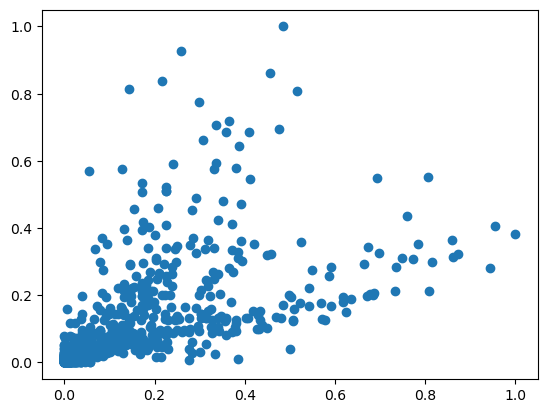

In [16]:
bbc_data = Apr_2_Oct_Station_events_dict['bbc']
plt.scatter(bbc_data.Delta_sm_10, bbc_data.Total_Precipitation_in)

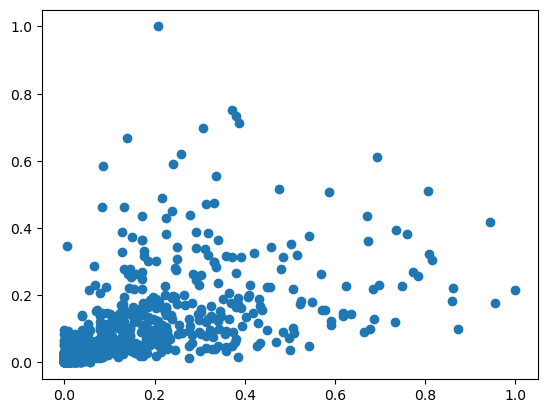

In [17]:
plt.scatter(bbc_data.Delta_sm_10, bbc_data.Peak_Precipitation_rate_in)

In [36]:
Apr_2_Oct_Station_events_dict['bvl']

,Event_Duration,Avg_Precipitation_rate_in,Peak_Precipitation_rate_in,Median_Precipitation_rate_in,Total_Precipitation_in,Prior_sm_10,Peak_sm_10,Prior_sm_100,Peak_sm_100,Delta_sm_10,Delta_sm_10_perPtot,Delta_sm_100,Delta_sm_100_perPtot
1297,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,NaN,0.000000,NaN
1298,9.0,0.088397,0.072388,0.073384,0.133790,0.784410,0.49250,0.792367,0.349500,0.287226,0.029283,0.175546,0.025131
1299,36.0,0.019964,0.134807,0.000000,0.120862,0.823878,0.49250,0.819541,0.349250,0.226757,0.025591,0.106854,0.016933
1300,9.0,0.061347,0.072822,0.043098,0.092850,0.799211,0.43750,0.804101,0.341250,0.098262,0.014435,0.096169,0.019838
1301,28.0,0.033946,0.076723,0.007571,0.159843,0.804144,0.50000,0.812129,0.351500,0.279667,0.023865,0.138910,0.016645
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1955,25.0,0.041188,0.266580,0.000000,0.173164,0.427232,0.29950,0.563859,0.308125,0.250945,0.019767,0.487712,0.053944
1956,1.0,0.003494,0.001300,0.003494,0.000588,0.570301,0.28975,0.682189,0.276100,0.002268,0.052632,0.000000,0.000000
1957,11.0,0.094139,0.132640,0.072219,0.174143,0.396152,0.31975,0.580966,0.264075,0.359788,0.028181,0.176462,0.019408
1958,9.0,0.130978,0.247074,0.034945,0.198237,0.438579,0.33275,0.573184,0.314125,0.334089,0.022987,0.501298,0.048434


# KDE cannot handle NaN or inf, so events that have NaN sm due to impossible values need to be dropped
there are likely nan values in the other sm columns like max, sum, etc but the .max() function ignores those so only events where the prior sm=nan need to be droppped but sm = nan during a storm event could mean the sensor is erroneous for the event. For now they are kept


In [30]:
def pdf_generation(data,bw_scale):

    kde_combined_results =[]
    column_min_max_values = []
    band_widths_ind_vals = []
    band_widths_joint_vals = []
    #pull out the precipitation columns and delta columns 
    first_df = next(iter(data.values()))
    precipitation_columns = first_df.columns[first_df.columns.str.contains('Precipitation|Prior')].tolist()
    delta_sm_columns =  first_df.columns[first_df.columns.str.contains('Delta')].tolist()

    
    for s, df in data.items():
        #s is the station key in the dictionary and df is specific dataframe 
        #calculate individual kdes
        print('Station:', s)
        for col in df.columns:
            #print('column', df[col])
            #print('nan?',df[col].isna().sum())
            #print('inf?',np.isinf(df[col]).sum())
            col_min = np.round(df[col].min(), decimals=2)
            col_max = np.round(df[col].max(), decimals=2)
            column_min_max_values.append((s, col, col_min, col_max))

            if col in precipitation_columns:
                #calculate joint probabilities
                for Dsm_col in delta_sm_columns:

                    if col == 'Total_Precipitation_in' and "Ptot" in Dsm_col:
                        continue

                    delta_sm_data = df[Dsm_col]
                    precip_col = df[col]
                    print('delta column:', Dsm_col)
                    print('precip col:', col)

                    paired_data = np.vstack([precip_col, delta_sm_data])
                    joint_kde = stats.gaussian_kde(paired_data, bw_method= 'scott')
                    joint_kde.set_bandwidth(bw_method = joint_kde.scotts_factor() * bw_scale)
                    joint_bw_x = joint_kde.factor * np.sqrt(joint_kde.covariance[0,0])
                    joint_bw_y = joint_kde.factor * np.sqrt(joint_kde.covariance[1,1])
                    joint_bw = [joint_bw_x, joint_bw_y]
                    joint_label = f'jointkde_{col}_{Dsm_col}'

                    #append the joint to the combined list
                    kde_combined_results.append((s, joint_label, joint_kde, 'joint'))
                    band_widths_joint_vals.append((s, joint_bw, joint_label))


            #calculate individual kdes
            kde = stats.gaussian_kde(df[col], bw_method= 'scott')
            kde.set_bandwidth(bw_method= kde.scotts_factor() * bw_scale)
            ind_bw = kde.factor * np.std(df[col])
            band_widths_ind_vals.append((s, ind_bw, col))
            kde_combined_results.append((s, col, kde, 'individual'))

    #check shape of combined dataframe
    #for i, item in enumerate(kde_combined_results):
    #    print(f"Item {i}: length = {len(item)}, content = {item}")


    #convert results into a multiIndex df
    multi_kde_df = pd.DataFrame(kde_combined_results, columns = ['Station', 'Variable', 'KDE_Object', 
                                                                 'Type'])
    multi_kde_df.set_index(['Station', 'Variable', 'Type'], inplace = True)
    #print(multi_kde_df)

    min_max_df = pd.DataFrame(column_min_max_values, columns=['Station', 'Variable', 'Min', 'Max'])
    min_max_df.set_index(['Station', 'Variable'], inplace=True)

    band_widths_joint_df = pd.DataFrame(band_widths_joint_vals, columns = ['Station', 'bandwidth',
                                                                           'Variable'])
    
    band_widths_ind_df = pd.DataFrame(band_widths_ind_vals, columns = ['Station', 'bandwidth', 
                                                                       'Variable'])
    
    return multi_kde_df, min_max_df, band_widths_ind_df, band_widths_joint_df
    

In [31]:
#multi_station_pdf = pdf_generation(station_dfs)
#for band width scale, <1 shrinks the bandwidth >1 widens it causing more smoothing

Apr_2_Oct_multi_station_kdes, Apr_2_Oct_multi_station_min_max_df, Apr_2_Oct_multi_station_ind_bw, Apr_2_Oct_multi_station_joint_bw = pdf_generation(Apr_2_Oct_Station_events_dict, bw_scale = 1)

Station: bbc
delta column: Delta_sm_10
precip col: Avg_Precipitation_rate_in
delta column: Delta_sm_10_perPtot
precip col: Avg_Precipitation_rate_in
delta column: Delta_sm_100
precip col: Avg_Precipitation_rate_in
delta column: Delta_sm_100_perPtot
precip col: Avg_Precipitation_rate_in
delta column: Delta_sm_10
precip col: Peak_Precipitation_rate_in
delta column: Delta_sm_10_perPtot
precip col: Peak_Precipitation_rate_in
delta column: Delta_sm_100
precip col: Peak_Precipitation_rate_in
delta column: Delta_sm_100_perPtot
precip col: Peak_Precipitation_rate_in
delta column: Delta_sm_10
precip col: Median_Precipitation_rate_in
delta column: Delta_sm_10_perPtot
precip col: Median_Precipitation_rate_in
delta column: Delta_sm_100
precip col: Median_Precipitation_rate_in
delta column: Delta_sm_100_perPtot
precip col: Median_Precipitation_rate_in
delta column: Delta_sm_10
precip col: Total_Precipitation_in
delta column: Delta_sm_100
precip col: Total_Precipitation_in
delta column: Delta_sm_10


ValueError: array must not contain infs or NaNs

In [15]:
Apr_2_Oct_multi_station_joint_bw.loc[Apr_2_Oct_multi_station_joint_bw['Station'] == 'bbc']

,Station,bandwidth,Variable
0,bbc,"[0.002675976128226899, 0.005139263816751307]",jointkde_Avg_Precipitation_rate_in_Delta_sm_10
1,bbc,"[0.002675976128226899, 0.004581086630225303]",jointkde_Avg_Precipitation_rate_in_Delta_sm_100
2,bbc,"[0.003596596932658033, 0.005139263816751307]",jointkde_Peak_Precipitation_rate_in_Delta_sm_10
3,bbc,"[0.003596596932658033, 0.004581086630225303]",jointkde_Peak_Precipitation_rate_in_Delta_sm_100
4,bbc,"[0.0025662927676666477, 0.005139263816751307]",jointkde_Median_Precipitation_rate_in_Delta_sm_10
5,bbc,"[0.0025662927676666477, 0.004581086630225303]",jointkde_Median_Precipitation_rate_in_Delta_sm...
6,bbc,"[0.004349070618038426, 0.005139263816751307]",jointkde_Total_Precipitation_in_Delta_sm_10
7,bbc,"[0.004349070618038426, 0.004581086630225303]",jointkde_Total_Precipitation_in_Delta_sm_100


In [62]:
Apr_2_Oct_multi_station_ind_bw.loc[Apr_2_Oct_multi_station_ind_bw['Station'] == 'bbc']

,Station,bandwidth,Variable
0,bbc,6.182131,Event_Duration
1,bbc,0.025683,Avg_Precipitation_rate_in
2,bbc,0.034519,Peak_Precipitation_rate_in
3,bbc,0.024631,Median_Precipitation_rate_in
4,bbc,0.041741,Total_Precipitation_in
5,bbc,0.016805,Prior_sm_10
6,bbc,0.015857,Peak_sm_10
7,bbc,0.008120,Prior_sm_100
8,bbc,0.008277,Peak_sm_100
9,bbc,0.049325,Delta_sm_10


Note that the code above creates a dataframe of KDE objects that are indexed by station ids. 
After using .loc['station_id', 'KDE_Object'] you get a pandas.Series that is multiIndexed which looks like columns
so the 'Column' and 'Type' columns are actually indices which sort the kde_objects

using pandas.Series allows for easier label-based filtering for grouping and selection which is
better than a dictionary where you select via the key name

so for selection the following is needed rather than the typical .loc[] for a dataframe
 kde_Series = kde_dict_data.loc[(s, 'KDE_Object')]

        individuals_kde = kde_Series[kde_Series.index.get_level_values(1) == 'individual']


In [63]:
Apr_2_Oct_multi_station_min_max_df

Min     Max
Station Variable                                 
bbc     Event_Duration                1.0  198.00
        Avg_Precipitation_rate_in     0.0    1.00
        Peak_Precipitation_rate_in    0.0    1.00
        Median_Precipitation_rate_in  0.0    1.00
        Total_Precipitation_in        0.0    1.00
...                                   ...     ...
siu     Peak_sm_10                    0.0    0.49
        Prior_sm_100                  0.0    0.36
        Peak_sm_100                   0.0    0.38
        Delta_sm_10                   0.0    1.00
        Delta_sm_100                  0.0    1.00

[220 rows x 2 columns]

# Plotting KDE pdfs

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009144827586206897
bin num 30
Prior_sm_10
sm dx 0.009144827586206897
bin num 30
Peak_sm_10
sm dx 0.00952
bin num 16
Prior_sm_100
sm dx 0.009066666666666667
bin num 19
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


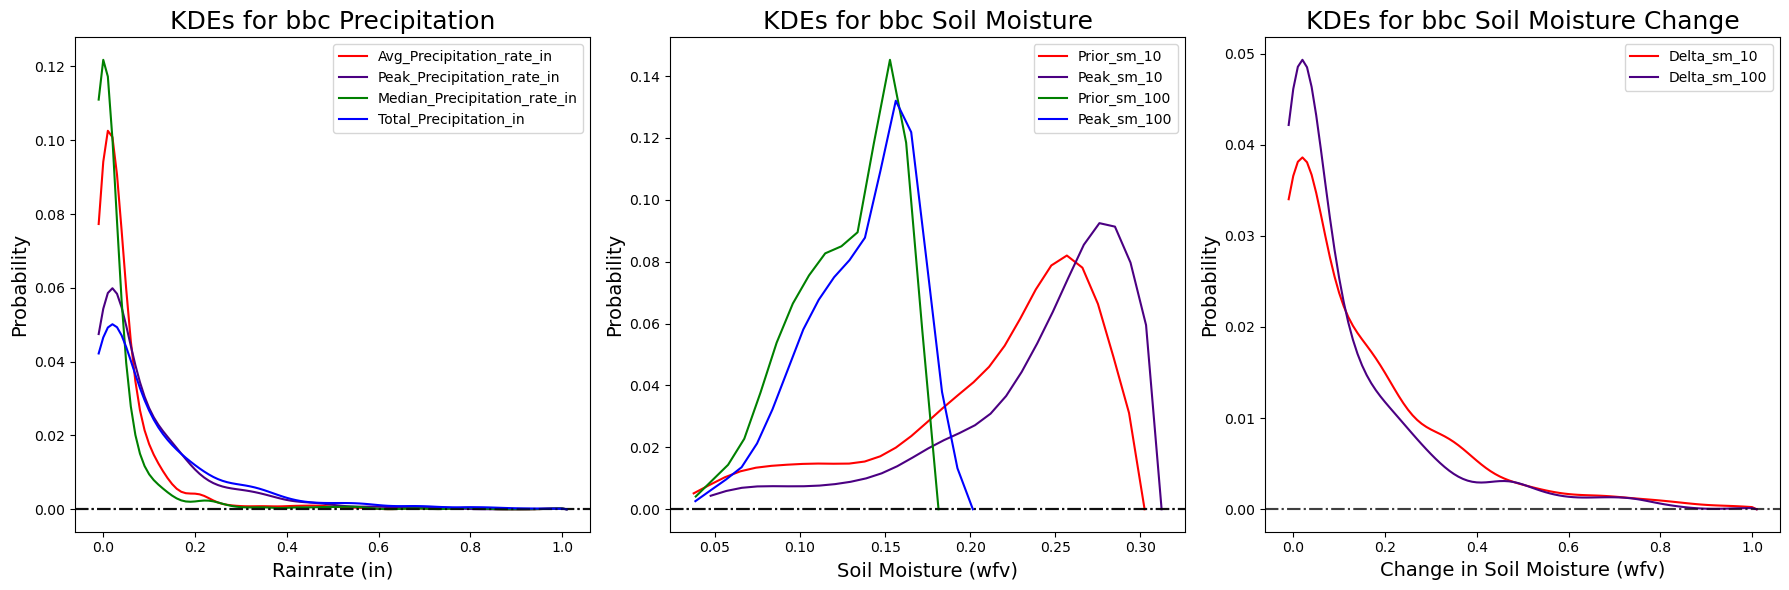

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009144827586206897
bin num 59
Prior_sm_10
sm dx 0.009126315789473677
bin num 58
Peak_sm_10
sm dx 0.00910714285714287
bin num 29
Prior_sm_100
sm dx 0.009066666666666667
bin num 28
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


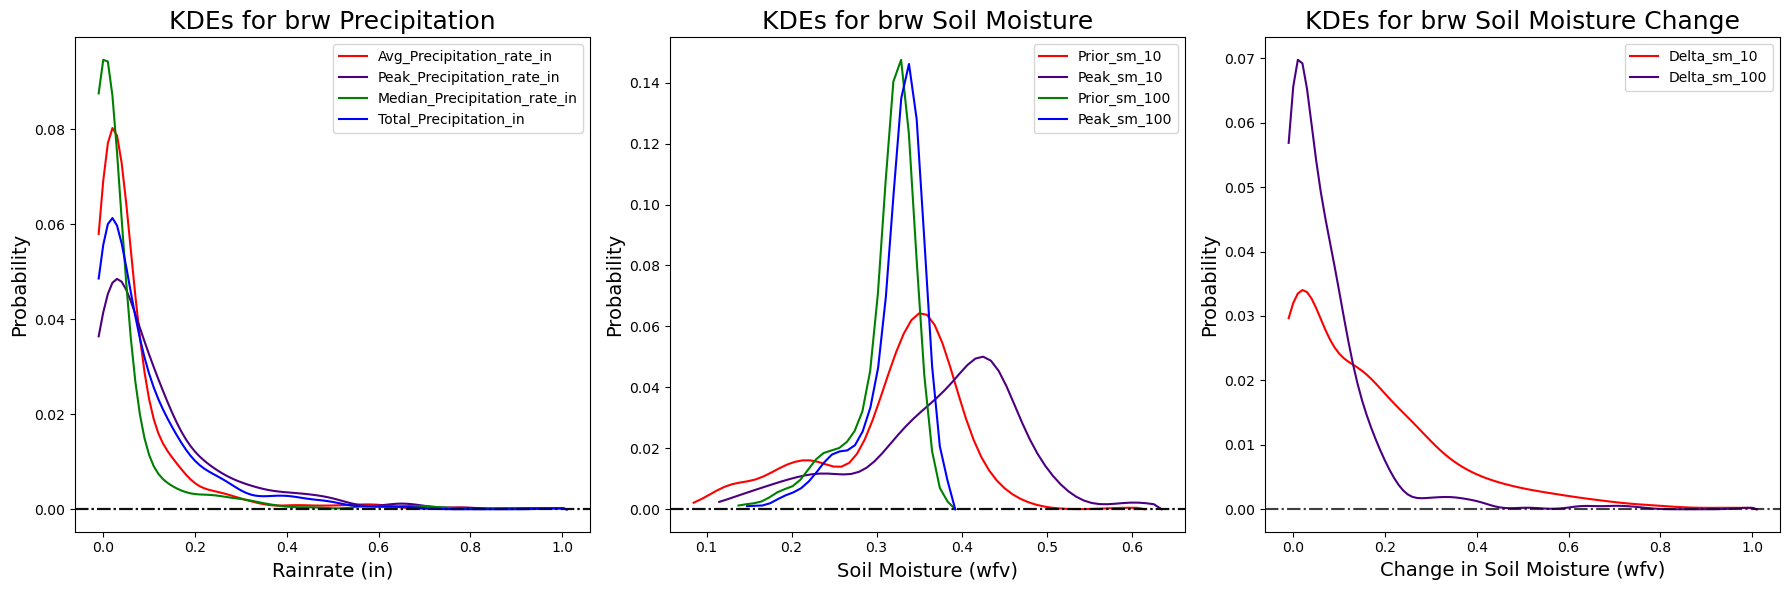

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009126315789473684
bin num 58
Prior_sm_10
sm dx 0.009029508196721311
bin num 62
Peak_sm_10
sm dx 0.009066666666666667
bin num 46
Prior_sm_100
sm dx 0.009091304347826085
bin num 47
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


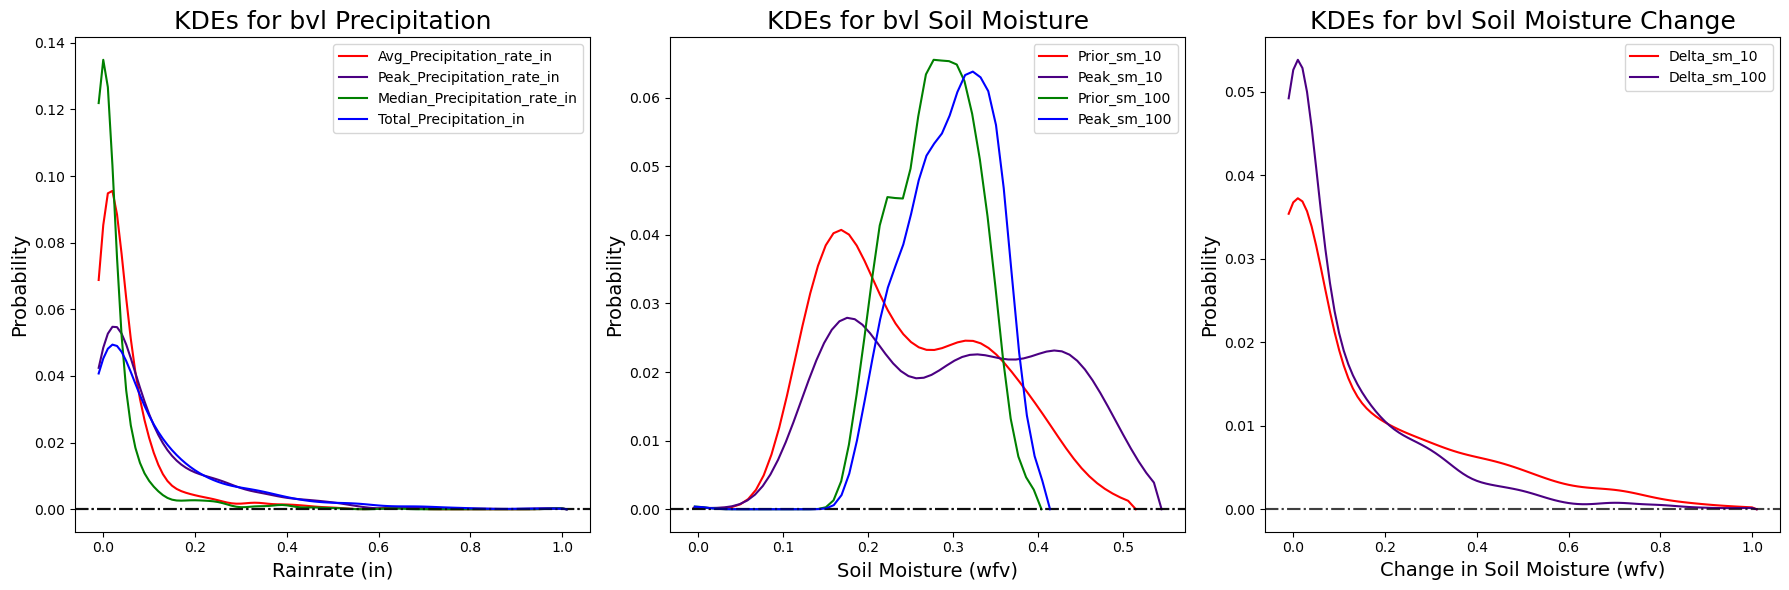

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009000000000000001
bin num 52
Prior_sm_10
sm dx 0.009029508196721311
bin num 62
Peak_sm_10
sm dx 0.009034285714285713
bin num 36
Prior_sm_100
sm dx 0.009097297297297299
bin num 38
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


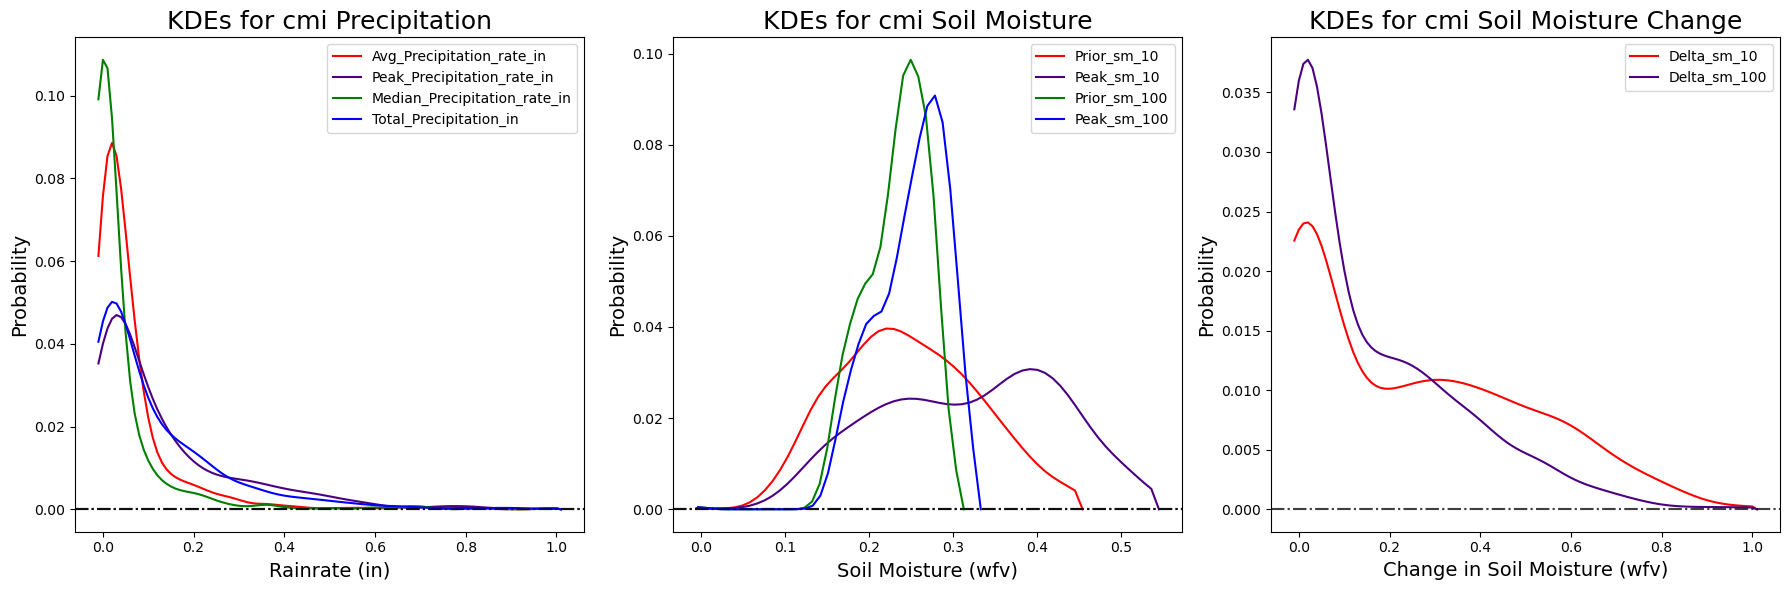

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009087272727272727
bin num 56
Prior_sm_10
sm dx 0.009009999999999999
bin num 61
Peak_sm_10
sm dx 0.009097297297297299
bin num 38
Prior_sm_100
sm dx 0.009126315789473686
bin num 39
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


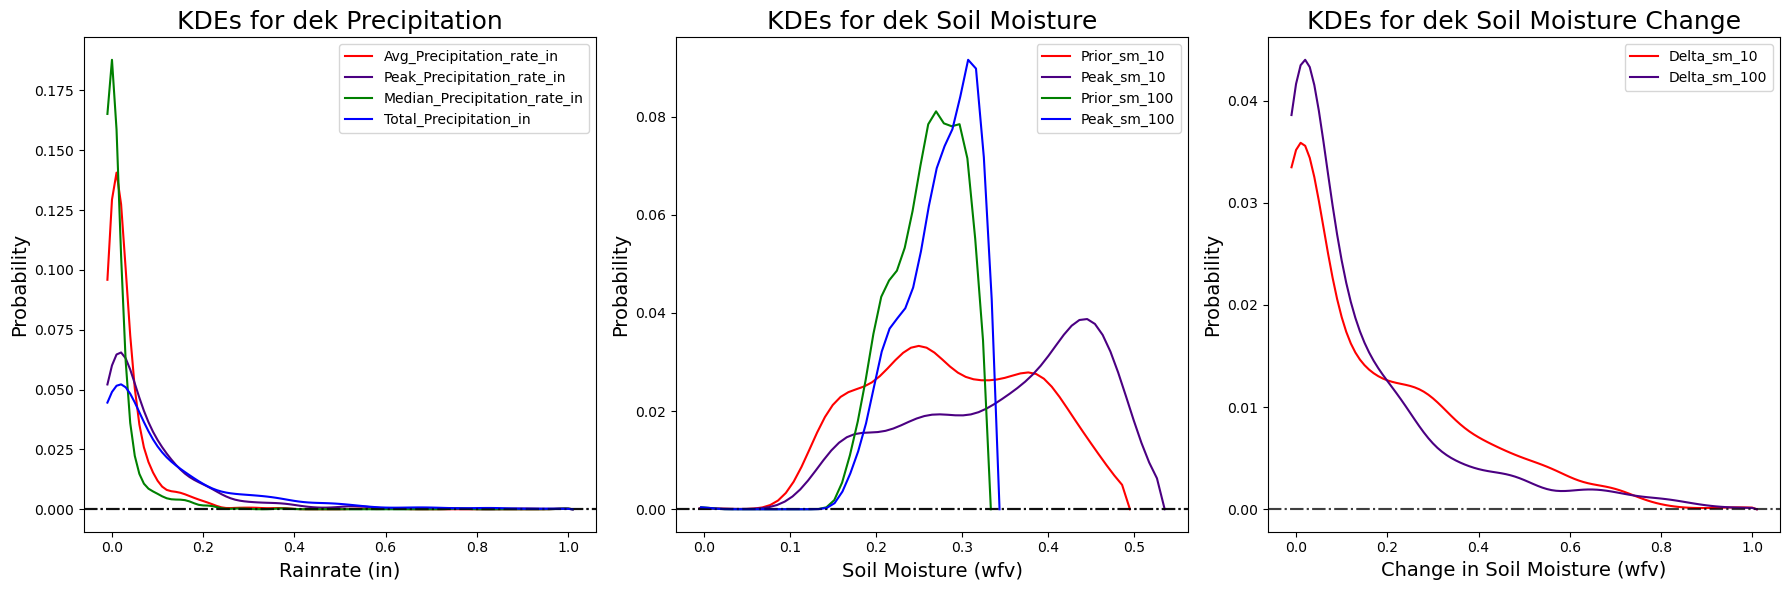

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009204878048780493
bin num 42
Prior_sm_10
sm dx 0.009091304347826082
bin num 47
Peak_sm_10
sm dx 0.009000000000000008
bin num 18
Prior_sm_100
sm dx 0.009126315789473677
bin num 20
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


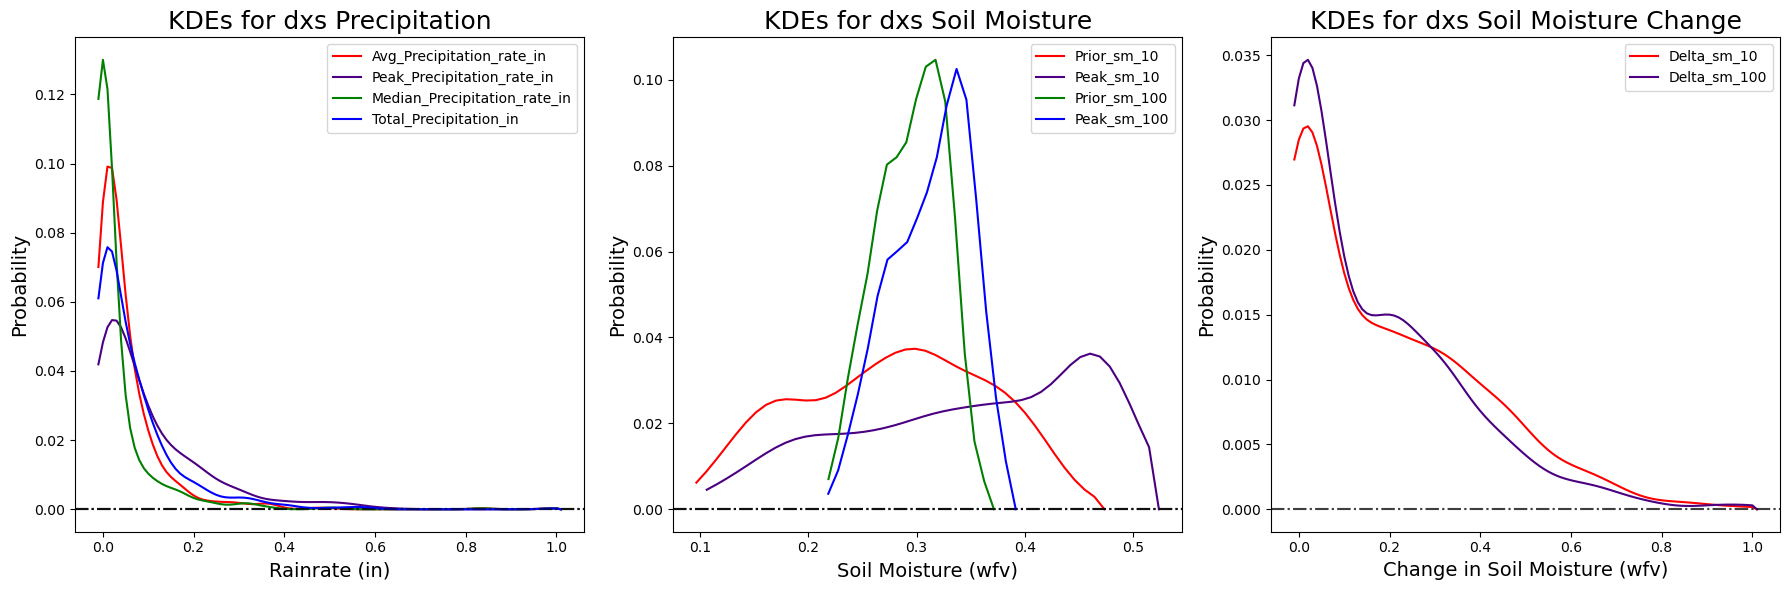

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009066666666666669
bin num 64
Prior_sm_10
sm dx 0.009101538461538461
bin num 66
Peak_sm_10
sm dx 0.009179999999999999
bin num 41
Prior_sm_100
sm dx 0.009040909090909093
bin num 45
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


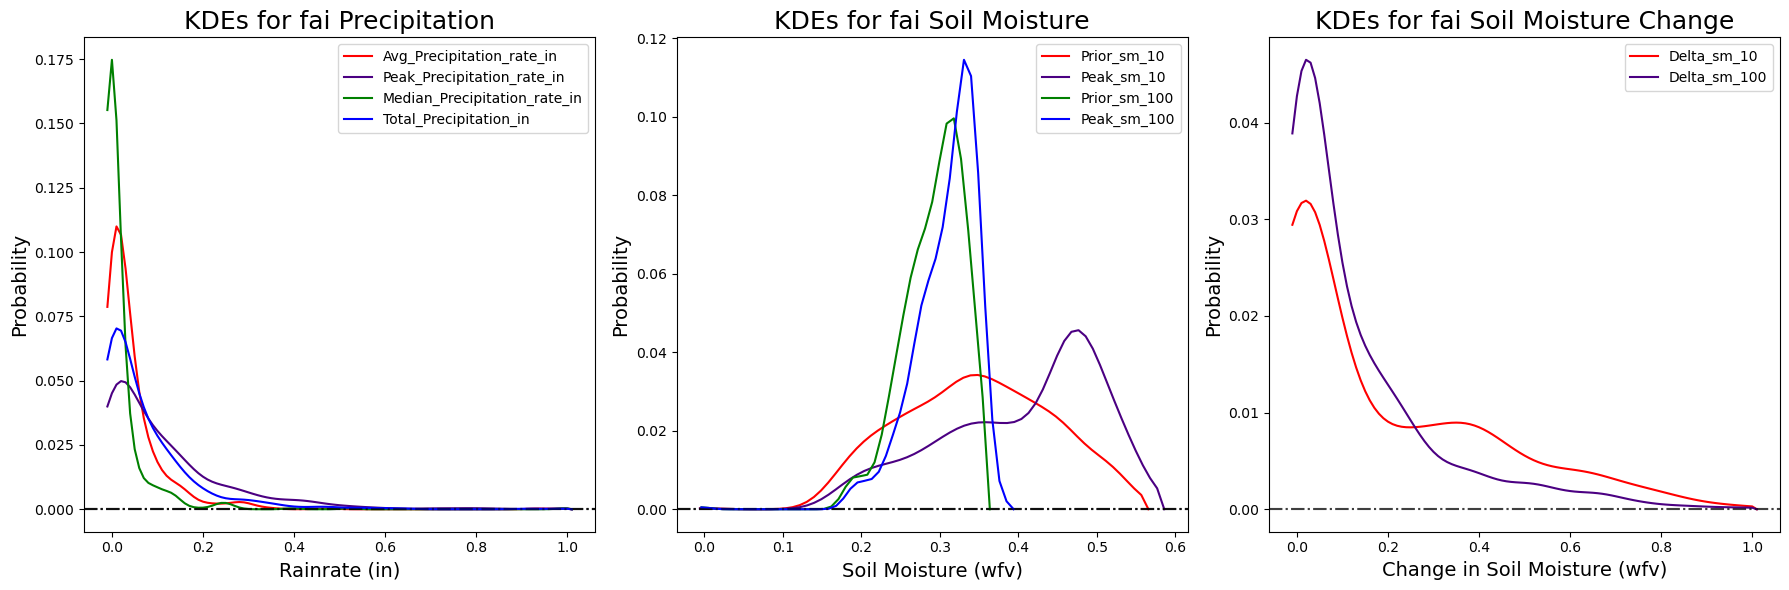

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009066666666666667
bin num 55
Prior_sm_10
sm dx 0.009066666666666669
bin num 64
Peak_sm_10
sm dx 0.009179999999999999
bin num 41
Prior_sm_100
sm dx 0.009040909090909093
bin num 45
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


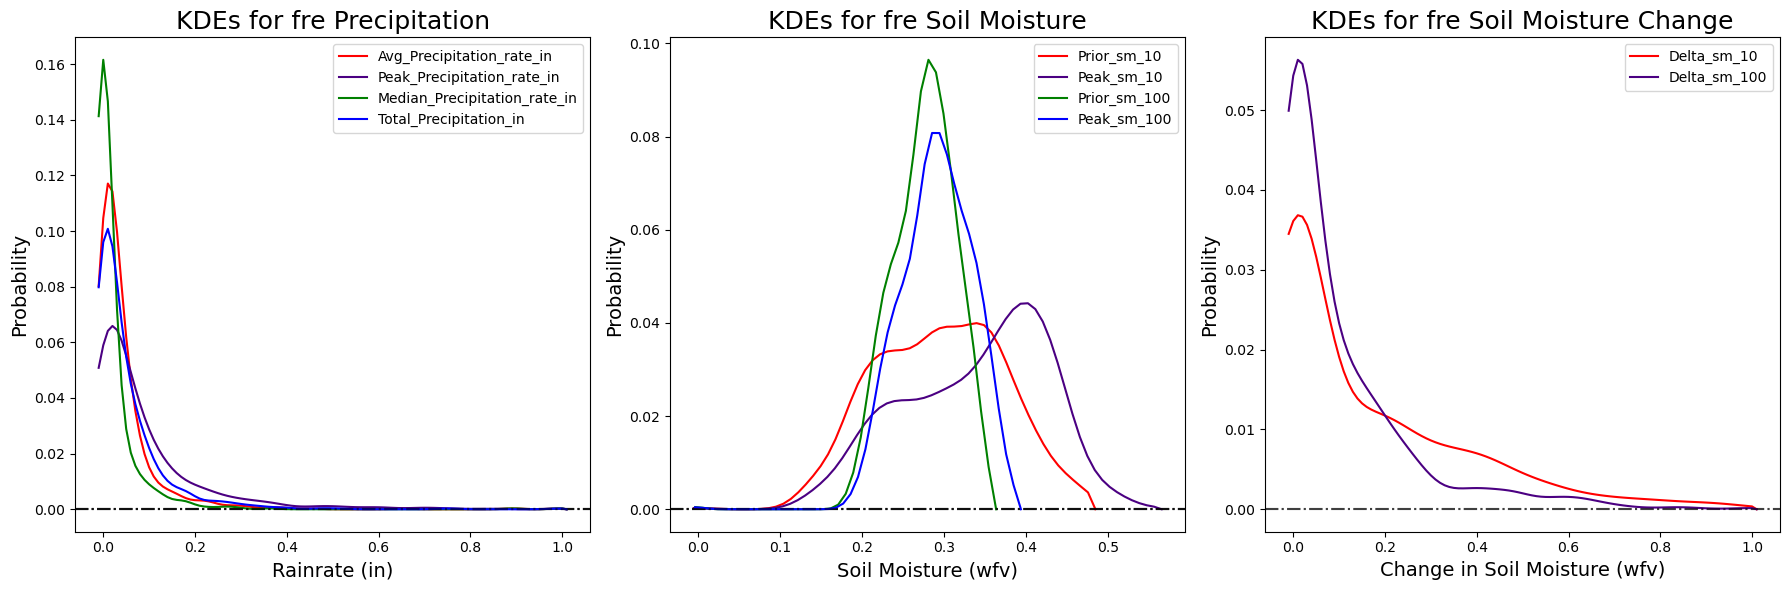

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009029508196721311
bin num 62
Prior_sm_10
sm dx 0.009017391304347824
bin num 70
Peak_sm_10
sm dx 0.009179999999999994
bin num 31
Prior_sm_100
sm dx 0.00910714285714287
bin num 29
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


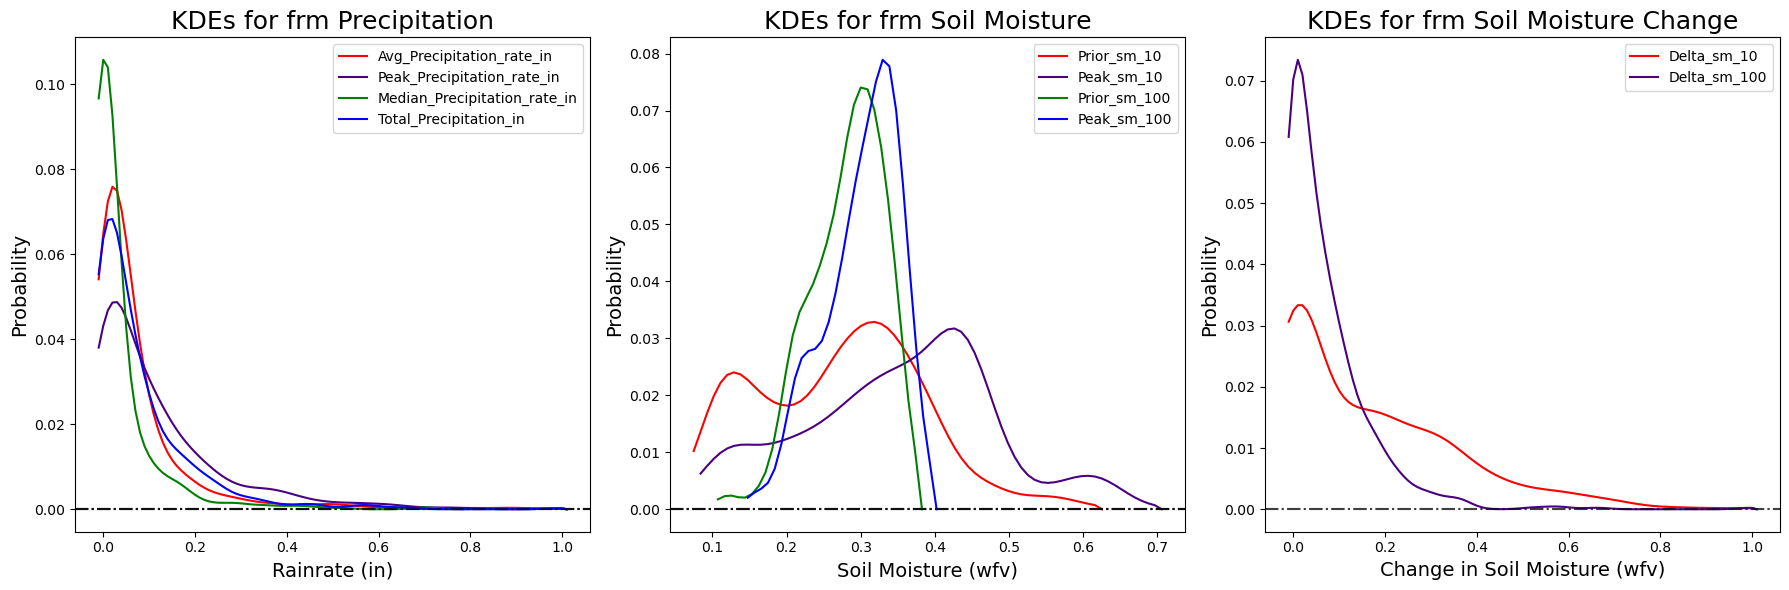

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009045283018867924
bin num 54
Prior_sm_10
sm dx 0.009087272727272727
bin num 56
Peak_sm_10
sm dx 0.009204878048780486
bin num 42
Prior_sm_100
sm dx 0.00915918367346939
bin num 50
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


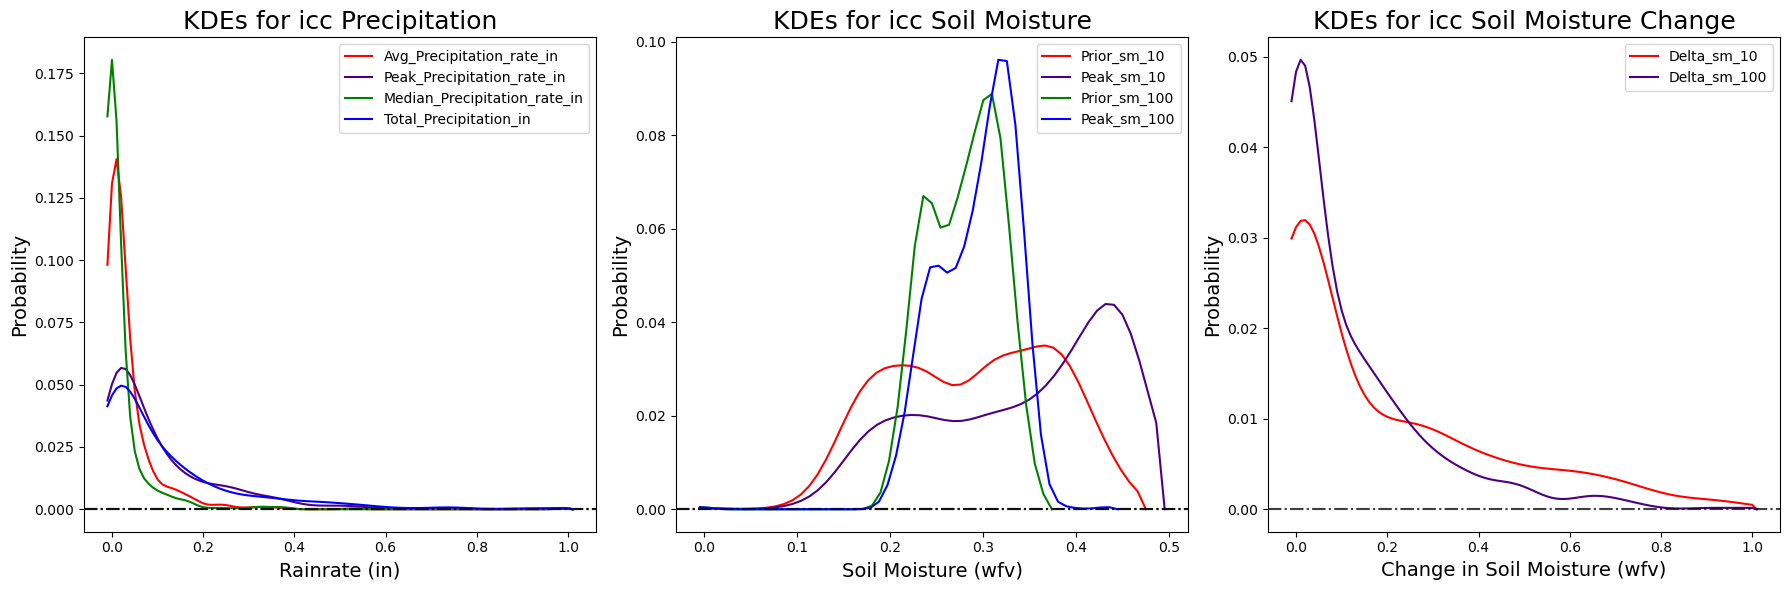

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009107142857142857
bin num 57
Prior_sm_10
sm dx 0.009126315789473684
bin num 58
Peak_sm_10
sm dx 0.009066666666666667
bin num 46
Prior_sm_100
sm dx 0.009091304347826085
bin num 47
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


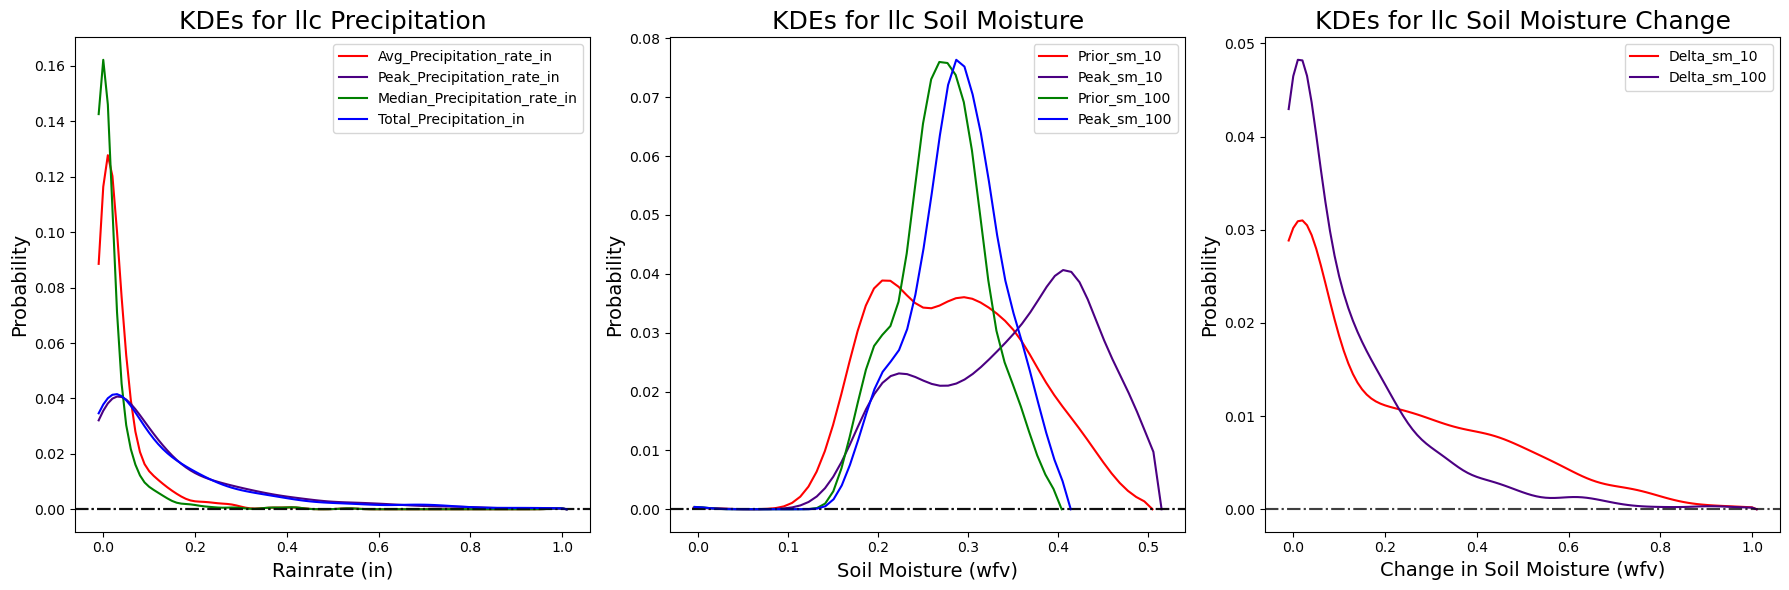

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.00915918367346939
bin num 50
Prior_sm_10
sm dx 0.009066666666666667
bin num 55
Peak_sm_10
sm dx 0.009066666666666666
bin num 37
Prior_sm_100
sm dx 0.009126315789473686
bin num 39
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


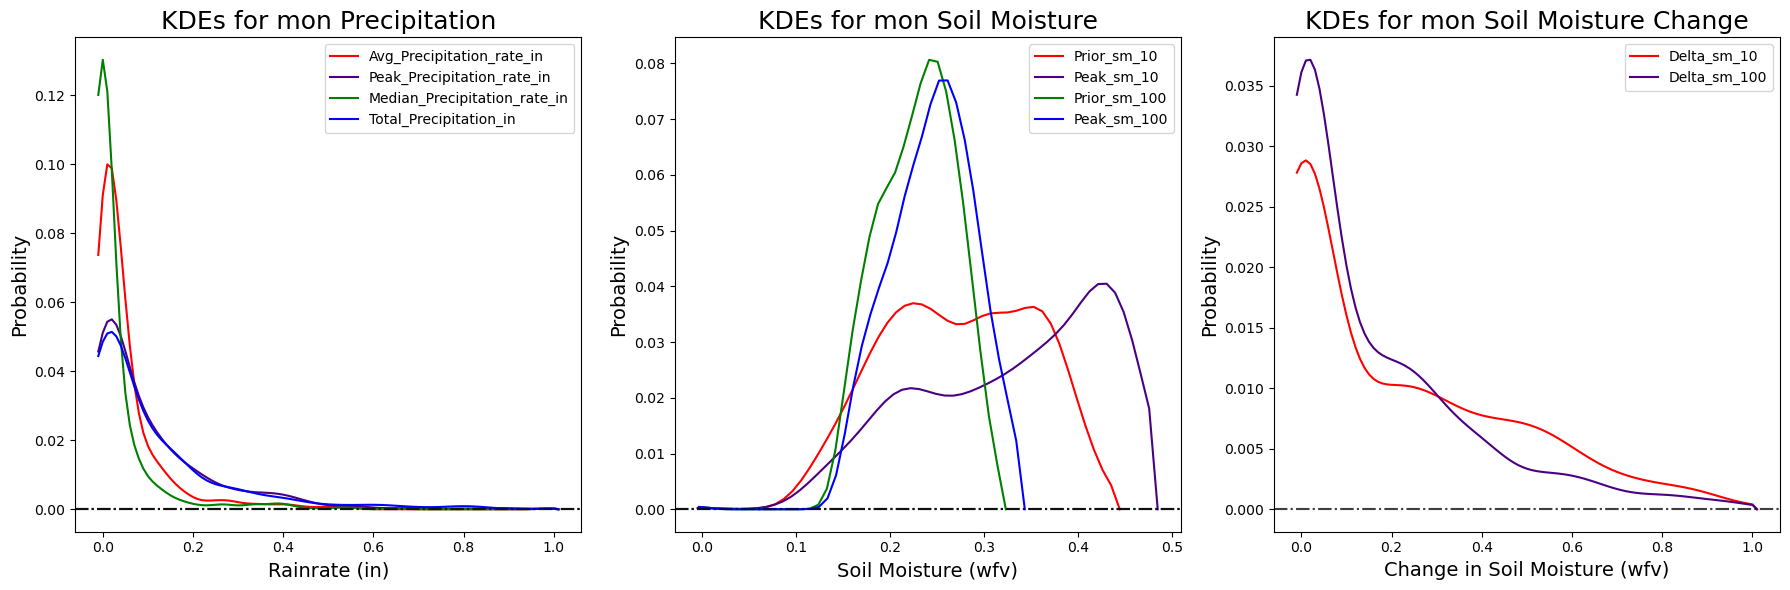

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009045283018867924
bin num 54
Prior_sm_10
sm dx 0.009034285714285713
bin num 71
Peak_sm_10
sm dx 0.009204878048780486
bin num 42
Prior_sm_100
sm dx 0.009013953488372094
bin num 44
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


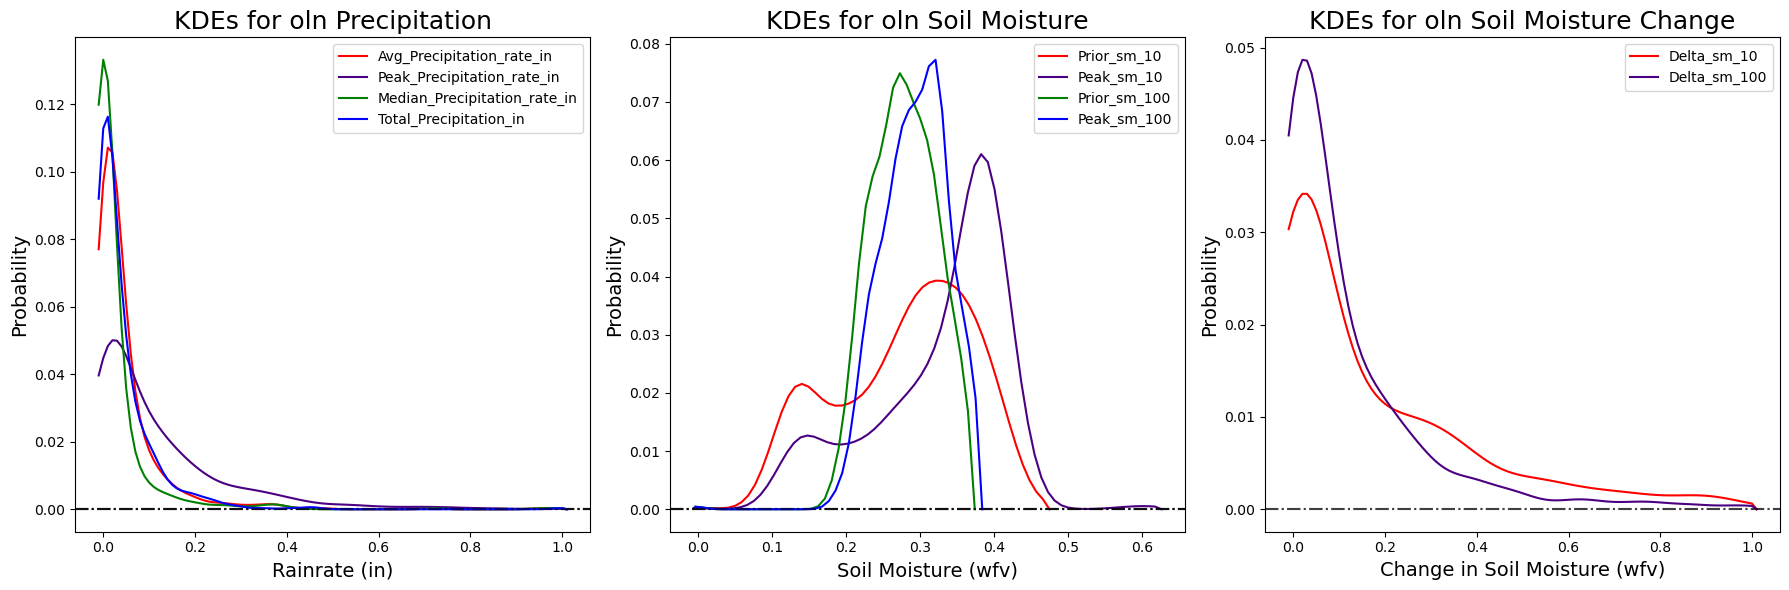

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009048387096774193
bin num 63
Prior_sm_10
sm dx 0.009101538461538461
bin num 66
Peak_sm_10
sm dx 0.009091304347826085
bin num 47
Prior_sm_100
sm dx 0.009091304347826085
bin num 47
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


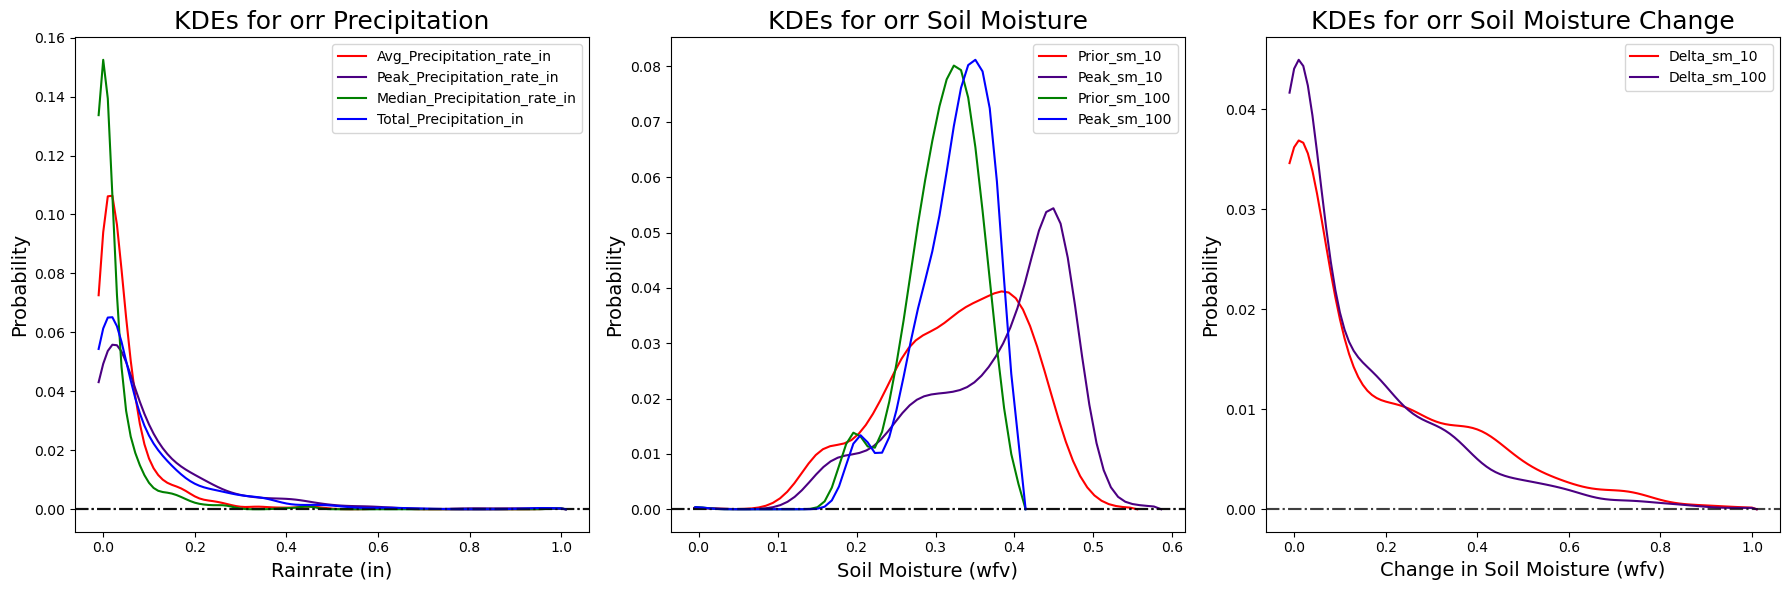

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009066666666666667
bin num 55
Prior_sm_10
sm dx 0.009029508196721311
bin num 62
Peak_sm_10
sm dx 0.009040909090909093
bin num 45
Prior_sm_100
sm dx 0.009066666666666667
bin num 46
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


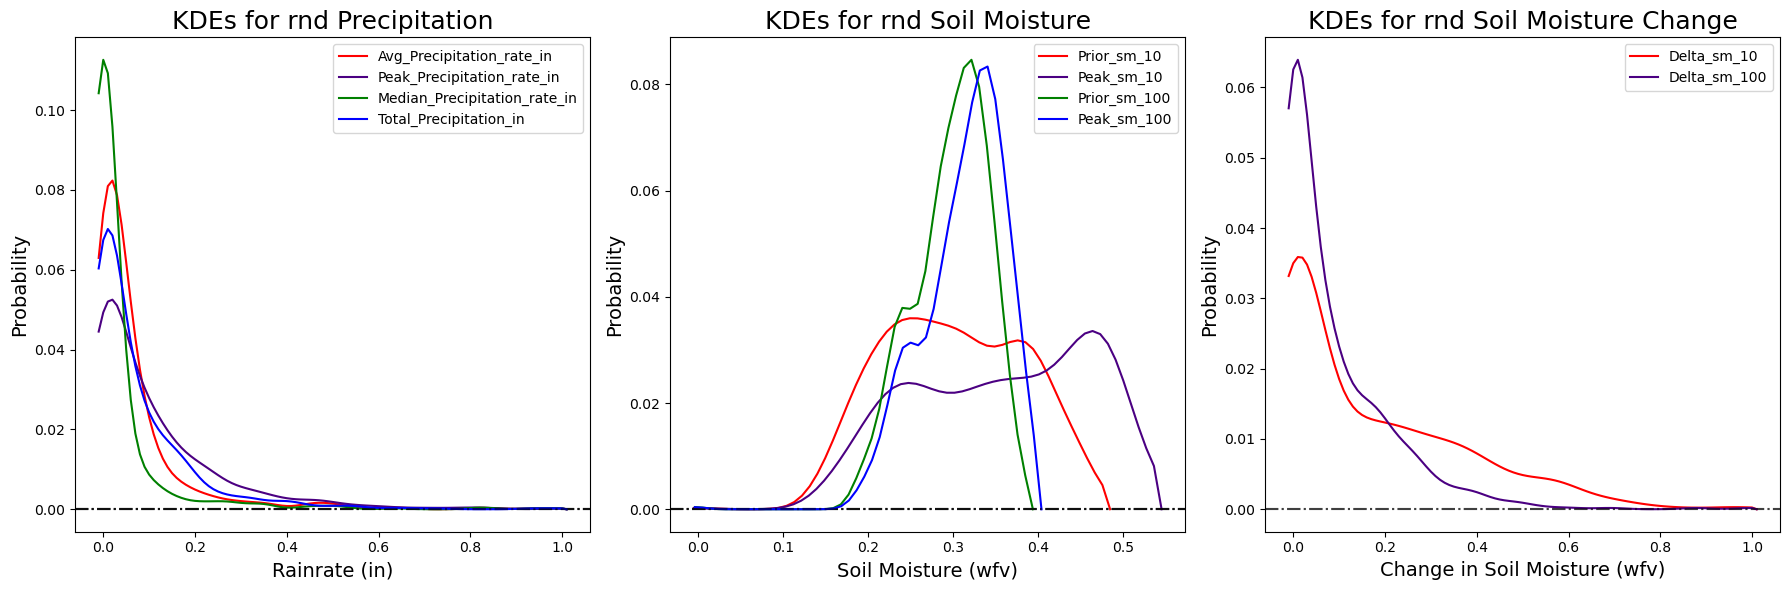

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009107142857142857
bin num 29
Prior_sm_10
sm dx 0.009144827586206897
bin num 30
Peak_sm_10
sm dx 0.009066666666666667
bin num 28
Prior_sm_100
sm dx 0.009066666666666667
bin num 28
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


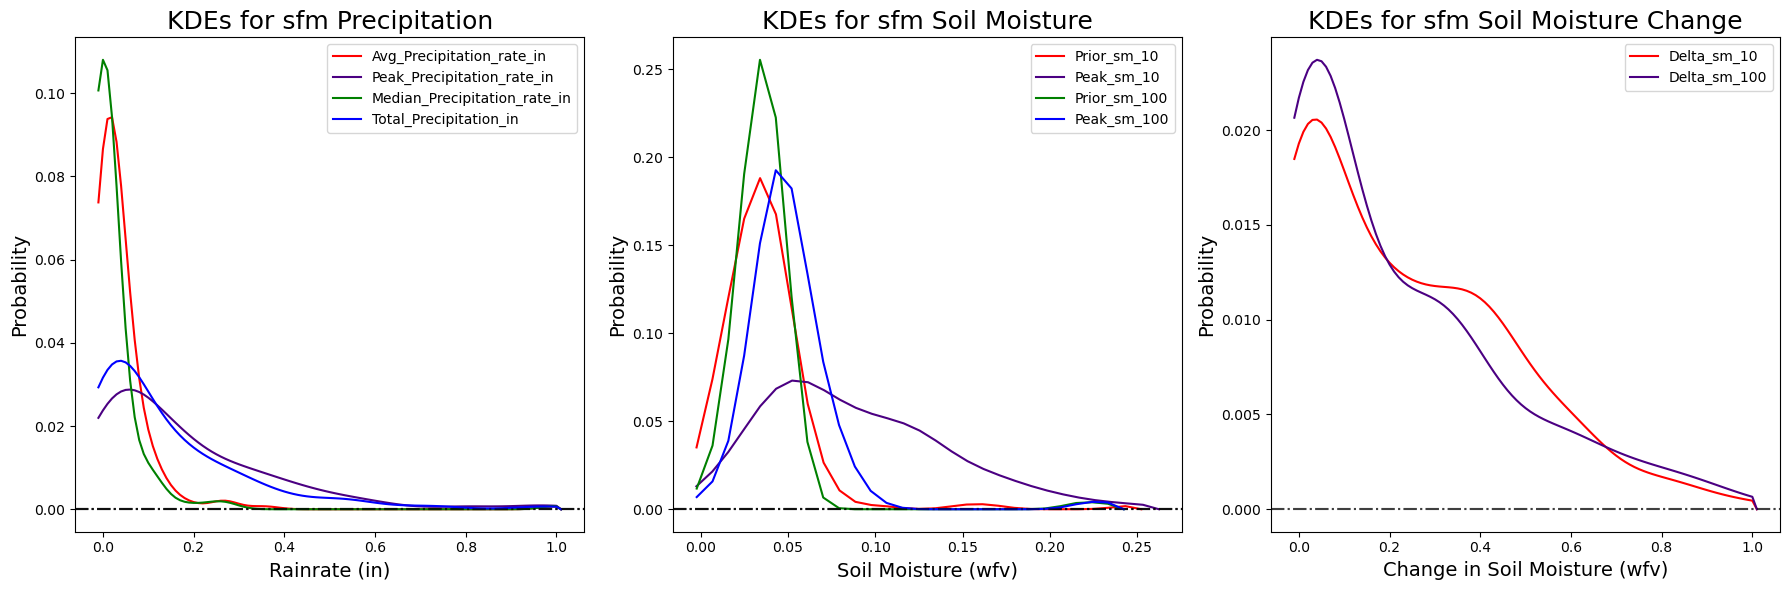

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009045283018867924
bin num 54
Prior_sm_10
sm dx 0.009087272727272727
bin num 56
Peak_sm_10
sm dx 0.009179999999999999
bin num 41
Prior_sm_100
sm dx 0.009013953488372094
bin num 44
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


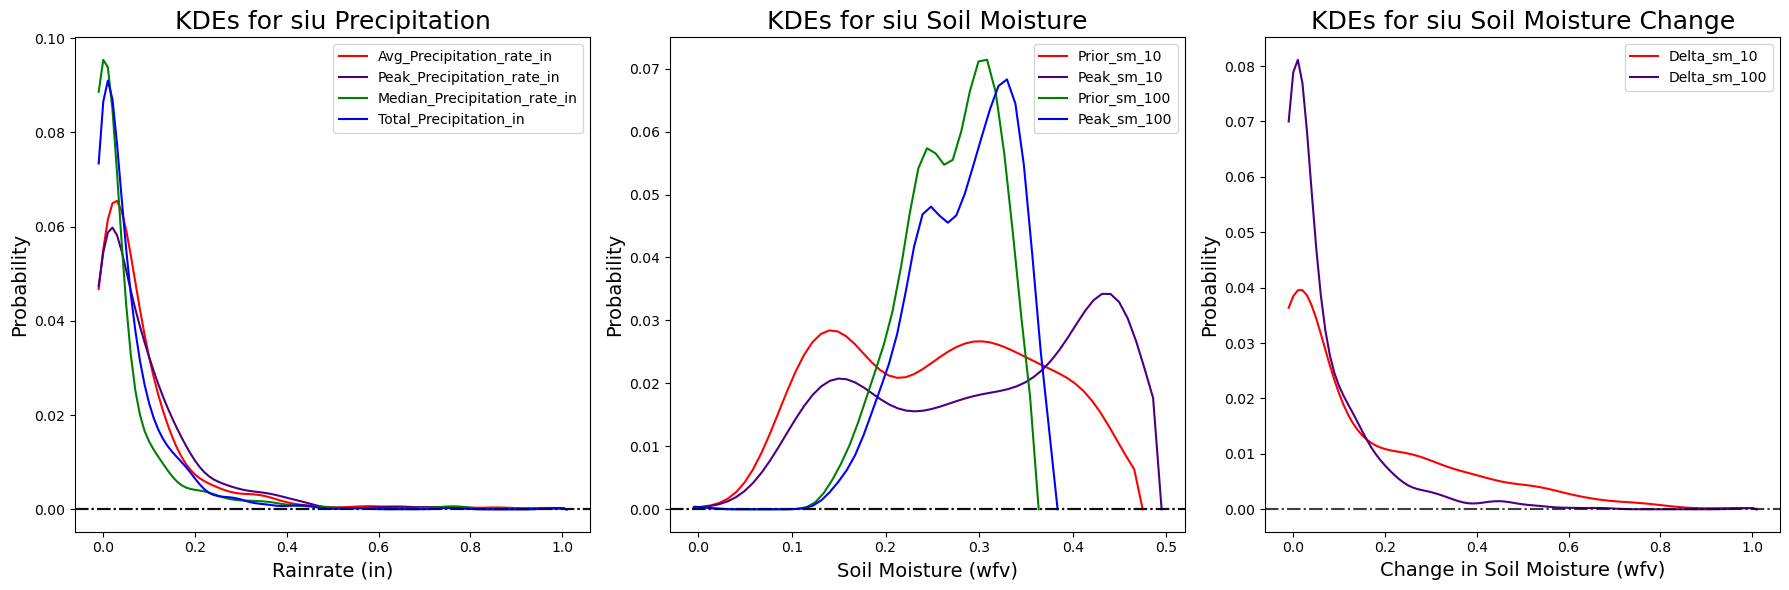

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009272727272727273
bin num 12
Prior_sm_10
sm dx 0.009066666666666667
bin num 28
Peak_sm_10
sm dx 0.0102
bin num 8
Prior_sm_100
sm dx 0.009520000000000002
bin num 16
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


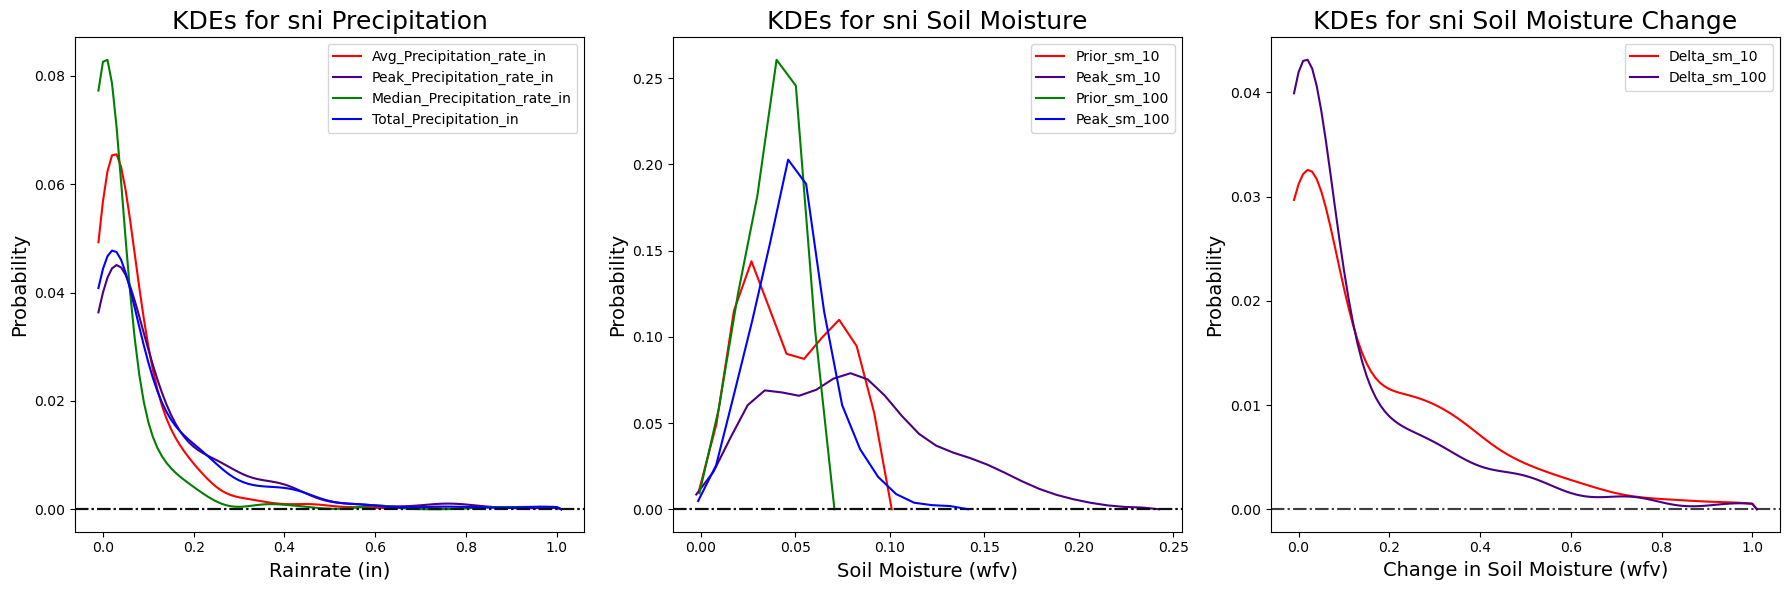

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.009091304347826085
bin num 47
Prior_sm_10
sm dx 0.009126315789473684
bin num 58
Peak_sm_10
sm dx 0.009097297297297299
bin num 38
Prior_sm_100
sm dx 0.009040909090909093
bin num 45
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


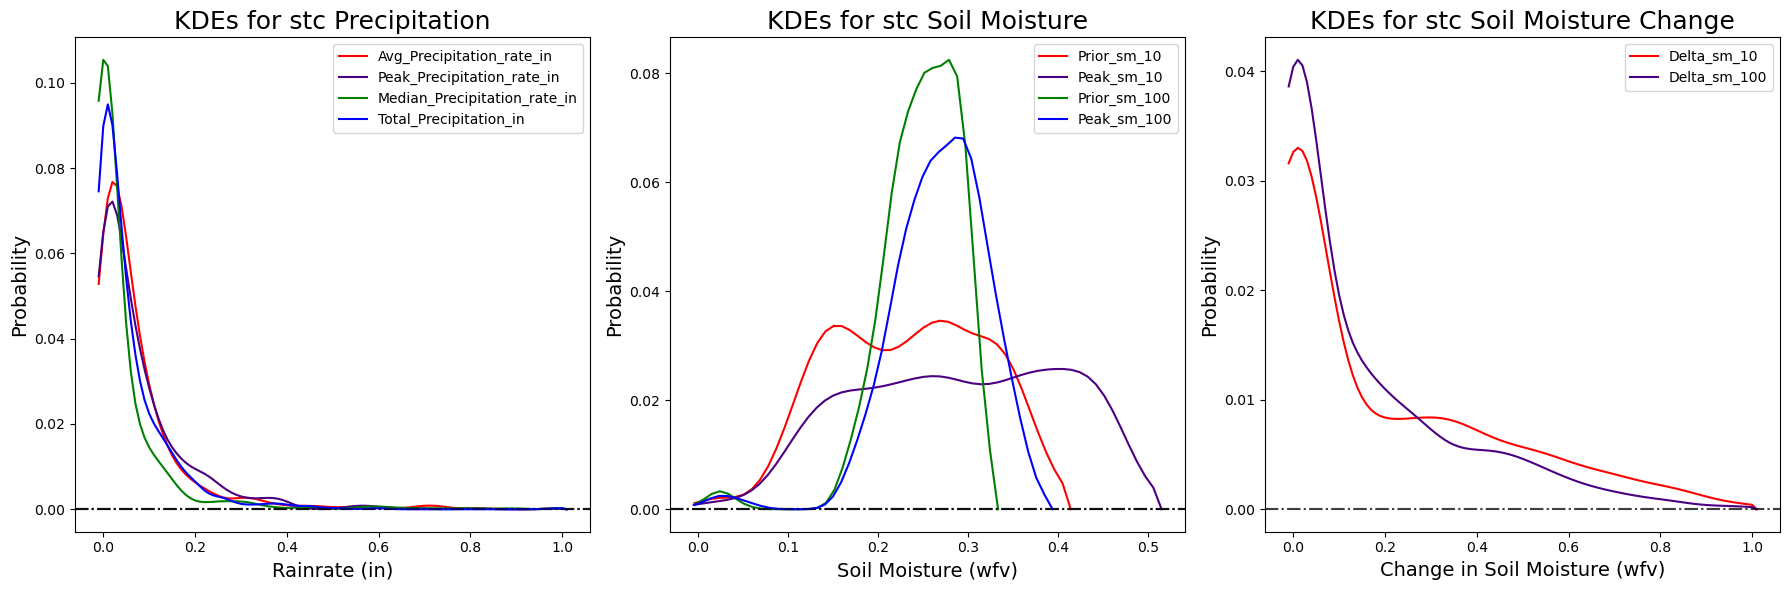

Precip dx 0.01
bin num 103
Avg_Precipitation_rate_in
Precip dx 0.01
bin num 103
Peak_Precipitation_rate_in
Precip dx 0.01
bin num 103
Median_Precipitation_rate_in
Precip dx 0.01
bin num 103
Total_Precipitation_in
sm dx 0.0090409090909091
bin num 45
Prior_sm_10
sm dx 0.009091304347826082
bin num 47
Peak_sm_10
sm dx 0.009313043478260868
bin num 24
Prior_sm_100
sm dx 0.009023076923076911
bin num 27
Peak_sm_100
delta dx 0.01
bin num 103
Delta_sm_10
delta dx 0.01
bin num 103
Delta_sm_100


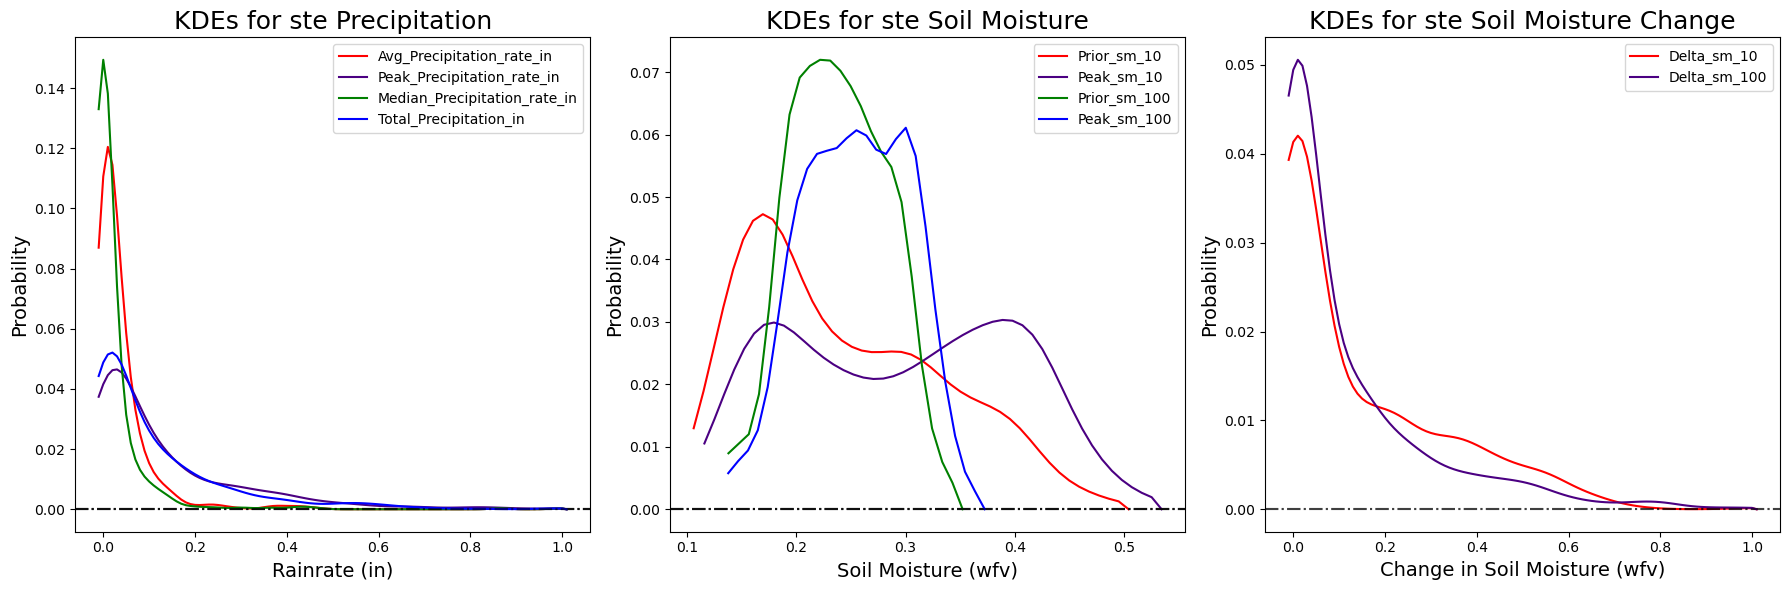

In [64]:
#plot the individual kdes
first_df = next(iter(Apr_2_Oct_Station_events_dict.values()))

#x_bin_num =100

precip_columns_to_plot = first_df.columns[first_df.columns.str.contains('Precipitation')].tolist()
sm_columns_to_plot = first_df.columns[
     first_df.columns.str.contains('sm') &  ~first_df.columns.str.contains('^Delta')].tolist() 
sm_delta_columns_to_plot = first_df.columns[first_df.columns.str.contains('Delta')].tolist()
color_list = ['red', 'indigo','green', 'blue']
Stations = Apr_2_Oct_multi_station_min_max_df.index.levels[0]
for s in Stations:
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    counter = 0
    for pcol in precip_columns_to_plot:
        kde = Apr_2_Oct_multi_station_kdes.loc[(s, pcol, 'individual'), 'KDE_Object']
        
        # Get min/max from min-max dataframe
        xmin = Apr_2_Oct_multi_station_min_max_df.loc[(s, pcol), 'Min']
        xmax = Apr_2_Oct_multi_station_min_max_df.loc[(s, pcol), 'Max']
        x_range_10precent = (xmax - xmin) / 100
        #it is considered good rule of thumb to extend the x_val range by 10% to capture kde probabilities correctly
        min_dx = 0.009
        dx_select = max(x_range_10precent, min_dx)
        x_bin_num = int(np.floor((xmax - xmin + 2*x_range_10precent)/dx_select)) +1
        x_vals = np.linspace(xmin - x_range_10precent, xmax + x_range_10precent, x_bin_num)
        dx = x_vals[1]-x_vals[0]
        print('Precip dx', dx)
        print('bin num', x_bin_num)

        pdf_vals = kde(x_vals)
        col_pvals = []
        for n in range(1, len(x_vals)+1):
                prob_n = simpson(pdf_vals[n - 1:n + 1], dx = dx) + 1e-12
                col_pvals.append(prob_n)

        if np.any(np.array(col_pvals)<= 1e-12):
              print(pcol)
              print("WARNING: p(x)<= 1e-12 -> numerically unstable for log2")

        ax[0].plot(x_vals, col_pvals, color=color_list[counter], label=f"{pcol}")
        ax[0].axhline(y=0, color ='black', linestyle = '-.', alpha=0.5)
        counter += 1

    ax[0].set_title(f"KDEs for {s} Precipitation", fontsize=18)
    ax[0].set_xlabel('Rainrate (in)', fontsize=14)
    ax[0].set_ylabel('Probability', fontsize=14)
    #ax[0].set_ylim(-0.001, 0.002)
    ax[0].legend()

    counter = 0
    for smcol in sm_columns_to_plot:
        kde = Apr_2_Oct_multi_station_kdes.loc[(s, smcol, 'individual'), 'KDE_Object']
        
        xmin = Apr_2_Oct_multi_station_min_max_df.loc[(s, smcol), 'Min']
        xmax = Apr_2_Oct_multi_station_min_max_df.loc[(s, smcol), 'Max']
        x_range_10precent = (xmax - xmin) / 100
        min_dx = 0.009
        dx_select = max(x_range_10precent, min_dx)
        x_bin_num = int(np.floor((xmax - xmin + 2*x_range_10precent)/dx_select)) +1
        x_vals = np.linspace(xmin - x_range_10precent, xmax + x_range_10precent, x_bin_num)
        dx = x_vals[1]-x_vals[0]
        print('sm dx', dx)
        print('bin num', x_bin_num)

        pdf_vals = kde(x_vals)
        col_pvals = []
        for n in range(1, len(x_vals)+1):
                prob_n = simpson(pdf_vals[n - 1:n + 1], dx = dx) + 1e-12
                col_pvals.append(prob_n)

        if np.any(np.array(col_pvals)<= 1e-12):
              print(smcol)
              print("WARNING: p(x)<= 1e-12 -> numerically unstable for log2")

        ax[1].plot(x_vals, col_pvals, color=color_list[counter], label=f"{smcol}")
        ax[1].axhline(y=0, color ='black', linestyle = '-.', alpha=0.5)
        #ax[1].hist(Apr_2_Oct_Station_events_dict[s][smcol],
         #          color=color_list[counter], density=True, bins=20, alpha=0.25)
        counter += 1

    ax[1].set_title(f"KDEs for {s} Soil Moisture", fontsize=18)
    ax[1].set_xlabel('Soil Moisture (wfv)', fontsize=14)
    ax[1].set_ylabel('Probability', fontsize=14)
    #ax[1].set_ylim(-0.001, 0.002)
    ax[1].legend()

    counter = 0
    for deltcol in sm_delta_columns_to_plot:
        kde = Apr_2_Oct_multi_station_kdes.loc[(s, deltcol, 'individual'), 'KDE_Object']

        xmin = Apr_2_Oct_multi_station_min_max_df.loc[(s, deltcol), 'Min']
        xmax = Apr_2_Oct_multi_station_min_max_df.loc[(s, deltcol), 'Max']
        x_range_10precent = (xmax - xmin) / 100
        min_dx = 0.009
        dx_select = max(x_range_10precent, min_dx)
        x_bin_num = int(np.floor((xmax - xmin + 2*x_range_10precent)/dx_select)) +1
        x_vals = np.linspace(xmin - x_range_10precent, xmax + x_range_10precent, x_bin_num)
        dx = x_vals[1]-x_vals[0]
        print('delta dx', dx)
        print('bin num', x_bin_num)

        pdf_vals = kde(x_vals)
        col_pvals = []
        for n in range(1, len(x_vals)+1):
                prob_n = simpson(pdf_vals[n - 1:n + 1], dx = dx)  + 1e-12
                col_pvals.append(prob_n)
        
        if np.any(np.array(col_pvals)<= 1e-12):
              print(deltcol)
              print("WARNING: p(x)<= 1e-12 -> numerically unstable for log2")

        ax[2].plot(x_vals, col_pvals, color=color_list[counter], label=f"{deltcol}")
        ax[2].axhline(y=0, color ='black', linestyle = '-.', alpha=0.5)
       #ax[2].hist(Apr_2_Oct_Station_events_dict[s][deltcol],
        #           color=color_list[counter], density=True, bins=15, alpha=0.25)
        counter += 1

    ax[2].set_title(f"KDEs for {s} Soil Moisture Change", fontsize=18)
    ax[2].set_xlabel('Change in Soil Moisture (wfv)', fontsize=14)
    ax[2].set_ylabel('Probability', fontsize=14)
    #ax[2].set_ylim(-0.001, 0.002)
    ax[2].legend()

    plt.tight_layout()
    plt.show()

Delta_sm_10
Delta_sm_100


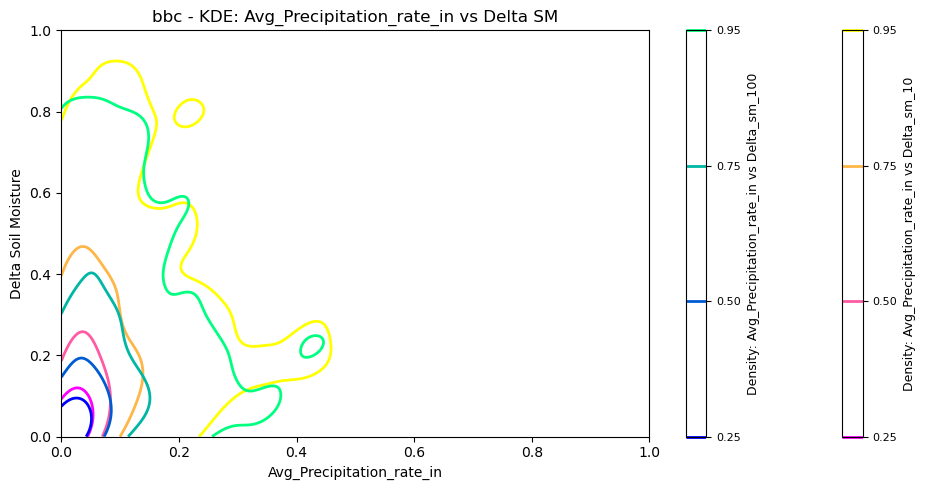

Delta_sm_10


KeyboardInterrupt: 

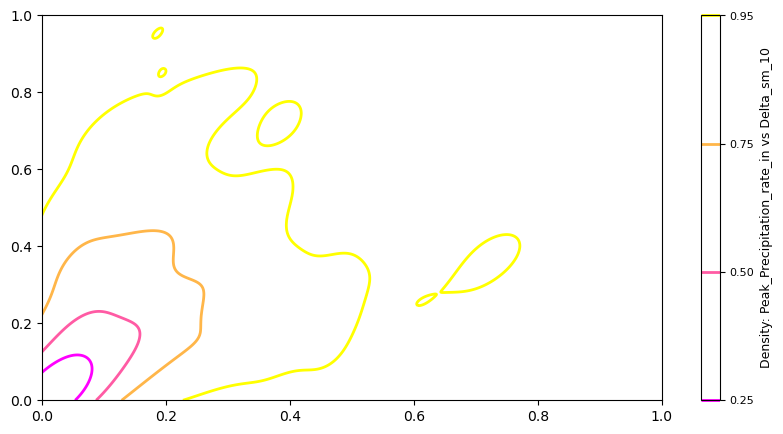

In [65]:
#plot the joint kdes as 3d plots
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib import colormaps

first_df = next(iter(Apr_2_Oct_Station_events_dict.values()))


precip_columns_to_plot = first_df.columns[first_df.columns.str.contains('Precipitation')].tolist()
sm_delta_columns_to_plot = first_df.columns[first_df.columns.str.contains('Delta')].tolist()
    
kde_dict = Apr_2_Oct_multi_station_kdes['KDE_Object'].to_dict()

for s in Apr_2_Oct_multi_station_kdes.index.levels[0]:
        for precip_col in precip_columns_to_plot :
            plt.figure(figsize=(10, 5))
            legend_proxies = []
            legend_labels = []
            c = 0
            for delta_col in sm_delta_columns_to_plot:
                kde = kde_dict.get((s, f'jointkde_{precip_col}_{delta_col}', 'joint'))
                if kde is None:
                    print(f"Missing KDE for {s}, {precip_col} vs {delta_col}")
                    continue

                # Get min/max for X and Y axes
                xmin = Apr_2_Oct_multi_station_min_max_df.loc[(s, precip_col), 'Min']
                xmax = Apr_2_Oct_multi_station_min_max_df.loc[(s, precip_col), 'Max'] #* 0.25
                ymin = Apr_2_Oct_multi_station_min_max_df.loc[(s, delta_col), 'Min']
                ymax = Apr_2_Oct_multi_station_min_max_df.loc[(s, delta_col), 'Max'] #* 0.5
                if xmin is None or ymin is None:
                    continue

                # Grid and KDE evaluation
                x_grid = np.linspace(xmin, xmax, 1000)
                y_grid = np.linspace(ymin, ymax, 1000)

                X, Y = np.meshgrid(x_grid, y_grid)
                positions = np.vstack([X.ravel(), Y.ravel()])
                Z = np.reshape(kde(positions), X.shape)
                Z_flat = Z.ravel()
                Z_sort_idx = np.argsort(Z_flat)[::-1]
                Z_sorted = Z_flat[Z_sort_idx]
                # Cumulative sum to get probability mass
                # Compute dx, dy for integration
                dx = x_grid[1] - x_grid[0]
                dy = y_grid[1] - y_grid[0]

                cumsum = np.cumsum(Z_sorted * dx * dy)
                cumsum /= cumsum[-1]  # Normalize to 1

                Z_cumsum = np.empty_like(Z_flat)
                Z_cumsum[Z_sort_idx] = cumsum
                Z_cumsum = Z_cumsum.reshape(Z.shape)

                # Choose contour levels (e.g. 50%, 75%, 95%)
                contour_levels = [0.25, 0.50, 0.75, 0.95]

                print(delta_col)

                color_schemes = ['spring', 'winter']
                # Plot the contours
                cmap = colormaps[color_schemes[c]]
                contour = plt.contour(X,Y,Z_cumsum, levels = contour_levels, linewidths = 2, cmap = cmap)
                #plt.clabel(contour, inline = True, fontsize=8, fmt="%.1f")

                cbar = plt.colorbar(contour)
                cbar.set_label(f'Density: {precip_col} vs {delta_col}', fontsize=9)
                cbar.ax.tick_params(labelsize=8)
            
                c+=1
               

            
            plt.xlabel(precip_col)
            plt.ylabel("Delta Soil Moisture")
            plt.title(f"{s} - KDE: {precip_col} vs Delta SM")
            plt.tight_layout()
            plt.show()





"""
#3d plots
for s in Apr_2_Oct_multi_station_kdes.index.levels[0]:
        num_rows = len(sm_delta_columns_to_plot)
        num_cols = len(precip_columns_to_plot)

        fig = plt.figure(figsize=(5 * num_cols, 5 * num_rows))
        fig.subplots_adjust(hspace=0.4, wspace=0.4)

        for row_idx, delta_col in enumerate(sm_delta_columns_to_plot):
            for col_idx, precip_col in enumerate(precip_columns_to_plot):
                ax = fig.add_subplot(num_rows, num_cols, row_idx * num_cols + col_idx + 1, projection='3d')

                # Try getting the KDE object
                kde = kde_dict.get((s, f'jointkde_{precip_col}_{delta_col}', 'joint'))
                if kde is None:
                    print(f"Missing KDE for {s}, {precip_col} vs {delta_col}")
                    continue

                # Get min/max for X and Y axes
                xmin = Apr_2_Oct_multi_station_min_max_df.loc[(s, precip_col), 'Min']
                xmax = Apr_2_Oct_multi_station_min_max_df.loc[(s, precip_col), 'Max']
                ymin = Apr_2_Oct_multi_station_min_max_df.loc[(s, delta_col), 'Min']
                ymax = Apr_2_Oct_multi_station_min_max_df.loc[(s, delta_col), 'Max']
                if xmin is None or ymin is None:
                    continue

                # Grid and KDE evaluation
                X, Y = np.meshgrid(np.linspace(xmin, xmax, 100), np.linspace(ymin, ymax, 100))
                positions = np.vstack([X.ravel(), Y.ravel()])
                Z = np.reshape(kde(positions), X.shape)

                # Plot the surface
                ax.plot_surface(X, Y, Z, cmap='hsv', edgecolor='none')
                ax.set_title(f"{precip_col} vs {delta_col}")
                ax.set_xlabel(precip_col)
                ax.set_ylabel(delta_col)
                ax.set_zlabel('Density')

            fig.suptitle(f"Joint KDE for {s}", fontsize=16)
            plt.show()
"""



# Calculating shannon's entropy and then the mutual information

shannon's entropy, H(X) = sum(p(x_i)*log(1/p(x_i))) = -sum(p(x_i)*log(p(x_i)))

Very small (e.g., < 1e-12) can cause log2(p) to explode negatively causing numerical instability in 
entropy estimations. Mask values below this to prevent the instability. Also set the dx and dy to have a floor of 0.001
to also avoid too small of probabilties. the log2(p_x) goes to -inf when it get small

mask out p(x) <=1e-12 to avoid the numerical instability or simply add 1e-12 to all the p(x) values, 
technically a shortcut, but common and since we are interested in the ratio of comparing the entropy and mi values and not their absolute values this is very defensible.

value this small are negligible to the total entropy but create major instability due to log2(0) -> -inf

for accurate capture of the pdf, the edge mass for the marginals needs to be 1e-5 for the joint it needs to be smaller 1e-6

dx for marginal needs to be around 0.001 for joint because the calculation is over a grid cell (area) the dx=dy needs to be larger. 
if grid cell resolution is too fine you get over estimation of joint, if it is too large you get under estimation. having dx and dy =0.001 gives an area of 1e-6 

mutual information, I(x,y) = H(x) - H(x|y) or H(y) - H(y|x) 
### or H(x) + H(y) - H(x,y)

normalized MI: Cxy = I(x,y)/H(y) and Cyx = I(x,y)/H(x)



H(x,y)min >= max(H(x), H(y))

MI <= min(H(x), H(y))


In [15]:
def calc_entropy(kde_df_Series_data, min_max_df,ind_bw, joint_bw):

    station_entropies = {}
    kde_df_Series_data = kde_df_Series_data.sort_index() 
    marginal_nbin = 1000
    joint_nbin=100
    n_joint_bw = 17
    n_marginal_bw = 5
    

    for s, group in kde_df_Series_data.groupby(level = 'Station'):
        print(s)

        kde_Series_all = kde_df_Series_data.loc[(s, 'KDE_Object')]
        kde_Series_select_vars = kde_Series_all[
            kde_Series_all.index.get_level_values(0).str.contains("Precipitation|Delta|Prior", 
                                                                        regex = True)]
        
        print(f"Filtered KDE variables for {s}: {kde_Series_select_vars}")

         # Ensure there are valid columns
        if kde_Series_select_vars.empty:
            print(f"⚠️ No valid KDE variables found for {s}")
            continue
      
        entropy_values = {}  # Dict to store values for one row  # DataFrame to store entropies for this station
       
        station_cols_min_vals = min_max_df.Min.loc[s]
        station_cols_max_vals = min_max_df.Max.loc[s]
        keep_vars = station_cols_min_vals.index.str.contains('Precipitation|Delta|Prior', regex = True)
        filtered_min_vals = station_cols_min_vals[keep_vars]
        filtered_max_vals = station_cols_max_vals[keep_vars]

        print(f"Filtered min values: {filtered_min_vals}")
        print(f"Filtered max values: {filtered_max_vals}")

        if filtered_min_vals.empty or filtered_max_vals.empty:
            print(f"⚠️ No valid min/max values for {s}")
            continue

        num_col = len(filtered_min_vals)

        H_cols = []
        for i in range(0,num_col):
            print(f"Processing column {i+1}/{num_col}")
            x_var_label = filtered_min_vals.index[i]
            col_min = filtered_min_vals.iloc[i]
            col_max = filtered_max_vals.iloc[i]

            print('current variable:', x_var_label)
            print('column min and max', (col_min, col_max))
            #pull in kde object for this column
            col_kde_objs = kde_Series_select_vars[
                kde_Series_select_vars.index.get_level_values(0).str.contains(x_var_label)]
            

            if col_kde_objs.empty:
                print(f"⚠️ No KDE object found for {x_var_label}")
                continue

            col_kde_ind = col_kde_objs[col_kde_objs.index.get_level_values(1) == 'individual']
            col_kde_ind_obj = col_kde_ind.iloc[0]
            #create x values to apply kde object to beased on data range
            #use datasets' min and max 

            x_bw = ind_bw.loc[(ind_bw['Station'] == s) & (ind_bw['Variable'] == x_var_label), 'bandwidth'].values[0]
           
            #it is considered good rule of thumb to extend the x_val range by 10% to 
            # capture kde probabilities correctly. For long taile distributions extend more
            
            x_bin_num = marginal_nbin 

            x_vals = np.linspace(col_min - x_bw*n_marginal_bw, col_max + x_bw*n_marginal_bw, x_bin_num)
            
            #apply kde to the x values array to produce densities 
            col_pdf_values = col_kde_ind_obj(x_vals)
            
            #calculate the integral of the pdf (area under curve) and then divide to normalize the pdf
            #(not super necessary as the intgeral is close to 1 already)
            col_integral = simpson(col_pdf_values, x = x_vals)
            col_norm = col_pdf_values / col_integral
            col_norm_integral = simpson(col_norm, x = x_vals)
            print("area (should be ~1)", col_integral)
            print("integral of normalized pdf = ", col_norm_integral)

            #check density at edges to make sure not cutting off excesive pdf values
            edge_vals = np.array([col_norm[0], col_norm[-1]])
            max_edge_density = np.max(edge_vals)
            print(f"🔍 Max density on edges of marginal PDF for {x_var_label}: {max_edge_density:.2e}")
            if max_edge_density > 1e-5:
                print(f"⚠️ Significant edge density detected for {x_var_label} — consider extending range further")



            #calculate the probabilities for each step in the x_vals
            dx = x_vals[1]-x_vals[0]
            col_pvals = []
            for n in range(1, len(x_vals)):
                prob_n = simpson(col_norm[n - 1:n + 1], dx = dx) 
                col_pvals.append(prob_n)
            
            col_pvals = np.array(col_pvals)

            #create mask for super low probabilities, they lead to instabilities in logarithm
            low_val_mask = col_pvals > 1e-12
            masked_pvals = col_pvals[low_val_mask]

            if np.any(np.array(col_pvals) <= 0):
                print("Warning: PDF has near-zero or negative values")

            
            #apply log base 2 to the pdfs, multiply by p then sum
            # - sum(pi*lg2(pi))
            #col_pvals is the probability mass function so the discretized formula can be used (don't add *dx)
            pdf_log2 = np.log2(masked_pvals)  

            H_cols = np.round(-np.sum(masked_pvals * pdf_log2), decimals = 12)
            if np.isnan(H_cols) or np.isinf(H_cols):
                print("Entropy result is unstable")

            print('entropy of this column =  ', H_cols)
            print('dx for this column =', dx)
            print('x bin number =', x_bin_num)
            entropy_values[x_var_label + "_entropy"] = H_cols

            if col_kde_ind.index.get_level_values(0).str.contains('Delta').any():
                print(f"Skipping joint KDE calculation for {x_var_label} due to 'Delta'")
                #we calculate the joints using the precip containing columns so to avoid double
                #calc of joint we have to skip 
                continue
            else:
                print('calculating the joint entropy')
                col_kde_joints = col_kde_objs[col_kde_objs.index.get_level_values(1) == 'joint']
                

                for (joint_label, col_kde_single_joint) in col_kde_joints.items():
                    print(f"Processing joint KDE for {joint_label}")
                    joint_kde_name = joint_label[0].replace("jointkde_", "")

                    # Ensure this joint KDE starts with the current x_var_label
                    if not joint_kde_name.startswith(x_var_label + "_"):
                        print(f"⚠️ Joint label '{joint_kde_name}' does not start with expected x_var '{x_var_label}'")
                        continue
                    y_var = joint_kde_name[len(x_var_label) + 1:]
                    print(f"Parsed y_var: {y_var}")

                    try:
                        y_min = filtered_min_vals[y_var]
                        y_max = filtered_max_vals[y_var]
                    except KeyError:
                        print(f"⚠️ Could not find min/max for {y_var}")
                        continue
                    

                    x_joint_bw = joint_bw.loc[(joint_bw['Station'] == s) & 
                                              (joint_bw['Variable'] == joint_label[0]), 
                                              'bandwidth'].values[0][0]

                    y_joint_bw = joint_bw.loc[(joint_bw['Station'] == s) & 
                                              (joint_bw['Variable'] == joint_label[0]), 
                                              'bandwidth'].values[0][1]
                    
                    #it is considered good rule of thumb to extend the x_val range by 10% to capture
                    # kde probabilities correctly
                    
                    y_bin_num = joint_nbin 
                    y_vals_delta = np.linspace(y_min - y_joint_bw*n_joint_bw, 
                                               y_max + y_joint_bw*n_joint_bw, y_bin_num)
                    dy = y_vals_delta[1]-y_vals_delta[0]

                    x_bin_num = joint_nbin 
                    x_vals = np.linspace(col_min - x_joint_bw*n_joint_bw, 
                                         col_max + x_joint_bw*n_joint_bw, x_bin_num)

                    #pair data in meshgrd and flatten to 2xN array for kde
                    X_precip, Y_delta =np.meshgrid(x_vals, y_vals_delta)
                    positions = np.vstack([X_precip.ravel(), Y_delta.ravel()])
                    Z_densities = np.reshape(col_kde_single_joint(positions), X_precip.shape)

                    # Normalize the joint density (integrate over all grid points (double integral))
                    joint_integral = simpson(simpson(Z_densities, dx = dy, axis = 0), dx=dx, axis = 0) #should sum to 1
                    joint_pdf = Z_densities / joint_integral  # Normalize to get probability distribution

                    edge_vals = np.hstack([
                    joint_pdf[0, :], joint_pdf[-1, :],  # Top and bottom edges
                    joint_pdf[:, 0], joint_pdf[:, -1]  # Left and right edges
                    ])
                    max_edge_density = np.max(edge_vals)
                    print(f"🔍 Max density on edges of joint PDF between {x_var_label} and {y_var}: {max_edge_density:.2e}")
                    if max_edge_density > 1e-5:
                        print("⚠️ Significant density near the edge — consider extending x/y " \
                        "ranges further,  ideally edge range below 1e-5")


                    # Compute joint probabilities using dx * dy integration
                    joint_pvals = joint_pdf * dx * dy  # Discretized probability mass function
                    print('column dx =', dx)
                    print('x bin num =', x_bin_num)
                    print('column dy =', dy)
                    print('y bin num=', y_bin_num)

                    # Compute log2 probabilities, avoiding log(0) by masking zeros
                    joint_pvals_flat = joint_pvals.ravel()
                    if np.any(np.array(joint_pvals_flat) <= 0):
                        print("Warning: PDF has near-zero or negative values")

                    #Remove small probabilities
                    joint_pvals_flat = joint_pvals_flat[joint_pvals_flat > 1e-12]  
                    log2_pvals = np.log2(joint_pvals_flat)

                    # Calculate joint entropy
                    H_joint = np.round(-np.sum(joint_pvals_flat * log2_pvals), decimals =12)
                    if np.isnan(H_joint) or np.isinf(H_joint):
                        print("Entropy result is unstable")

                    print(f'Joint entropy between {x_var_label} and {y_var}: {H_joint}')
                    entropy_values[f'joint_entropy_{x_var_label}_{y_var}'] = H_joint
        if entropy_values:
            entropy_df = pd.DataFrame([entropy_values])  # one row
            station_entropies[s] = entropy_df
        else:
            print(f"⚠️ No entropy values computed for station {s}")

    return station_entropies


In [16]:
Entropies = calc_entropy(Apr_2_Oct_multi_station_kdes, Apr_2_Oct_multi_station_min_max_df, Apr_2_Oct_multi_station_ind_bw, Apr_2_Oct_multi_station_joint_bw)          


bbc
Filtered KDE variables for bbc: Variable                                            Type      
Avg_Precipitation_rate_in                           individual    <scipy.stats._kde.gaussian_kde object at 0x149...
Delta_sm_10                                         individual    <scipy.stats._kde.gaussian_kde object at 0x149...
Delta_sm_100                                        individual    <scipy.stats._kde.gaussian_kde object at 0x149...
Median_Precipitation_rate_in                        individual    <scipy.stats._kde.gaussian_kde object at 0x149...
Peak_Precipitation_rate_in                          individual    <scipy.stats._kde.gaussian_kde object at 0x149...
Total_Precipitation_in                              individual    <scipy.stats._kde.gaussian_kde object at 0x149...
jointkde_Avg_Precipitation_rate_in_Delta_sm_10      joint         <scipy.stats._kde.gaussian_kde object at 0x149...
jointkde_Avg_Precipitation_rate_in_Delta_sm_100     joint         <scipy.stats._kde.gauss

In [15]:
#save data and kde df
import pickle

with open(r"/data/keeling/a/cstraus2/Phd_research/normalized_entropies_scale1_bw517_binn1000_and100_masked.pkl", "wb") as f:
    pickle.dump(Entropies, f)

In [16]:
Entropies['bbc']

,Avg_Precipitation_rate_in_entropy,joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10,joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100,Peak_Precipitation_rate_in_entropy,joint_entropy_Peak_Precipitation_rate_in_Delta_sm_10,joint_entropy_Peak_Precipitation_rate_in_Delta_sm_100,Median_Precipitation_rate_in_entropy,joint_entropy_Median_Precipitation_rate_in_Delta_sm_10,joint_entropy_Median_Precipitation_rate_in_Delta_sm_100,Total_Precipitation_in_entropy,joint_entropy_Total_Precipitation_in_Delta_sm_10,joint_entropy_Total_Precipitation_in_Delta_sm_100,Delta_sm_10_entropy,Delta_sm_100_entropy
0,7.464439,9.25044,9.054426,8.194736,9.544634,9.221828,7.212607,9.145304,8.949406,8.394744,9.639211,8.985021,8.667587,8.433663


# Calculate MI and normalized MI
normalized MI: Cxy = I(x,y)/H(y) and Cyx = I(x,y)/H(x)

In [17]:
def mutual_information_calc(entropies_dict):
    Stations = list(entropies_dict.keys())
    Station_MI = []

    for s in Stations:
        print('station', s)
        station_entropy_df = entropies_dict[s]
        # Step 1: Get columns for H(X) and H(Y) (without 'joint_' prefix)
        individual_columns = [col for col in station_entropy_df.columns if 'joint_' not in col]

        # Step 2: Get columns for H(X, Y) (with 'joint_' prefix)
        joint_columns = [col for col in station_entropy_df.columns if 'joint_' in col]
        mutual_information = {}
        for joint_col in joint_columns:
            found = False
            joint_label = joint_col.replace('joint_entropy_', '')
            print('Joint col', joint_col)
            print('Joint label', joint_label)

            for col_x in individual_columns:
                for col_y in individual_columns:
                    if col_x == col_y:
                        continue  # skip self-pairs

                    # Remove the '_entropy' suffix to get base names
                    col_x_base = col_x.removesuffix('_entropy')
                    col_y_base = col_y.removesuffix('_entropy')

                    expected_joint_col = f"joint_entropy_{col_x_base}_{col_y_base}"

                    if expected_joint_col == joint_col:
                        print('match found')
                        # Find the corresponding individual entropy columns
                        # Match found — calculate MI
                        H_X = station_entropy_df[col_x]
                        print('H_X', H_X)
                        H_Y = station_entropy_df[col_y]
                        print('H_Y', H_Y)
                        H_XY = station_entropy_df[joint_col]
                        print('H_XY', H_XY)

                        MI = H_X + H_Y - H_XY
                        MI_label = 'MI_'+ col_x + '_and_' + col_y

                        Cxy = np.round(MI/H_Y, decimals = 12)
                        Cyx = np.round(MI/H_X, decimals = 12)

                        for idx, val in MI.items():
                            Station_MI.append({
                                "station": s,
                                "index": idx,
                                "MI_label": MI_label,
                                "mutual_information": val,
                                "H(x)": col_x_base,
                                "C_xy":  Cxy,
                                "H(y)": col_y_base,
                                "C_yx": Cyx
                            })

                        found = True
                        break  # inner loop
                if found:
                    break  # outer loop   


    return pd.DataFrame(Station_MI)

In [19]:
MIs = mutual_information_calc(Entropies)

station bbc
Joint col joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10
Joint label Avg_Precipitation_rate_in_Delta_sm_10
match found
H_X 0    7.464439
Name: Avg_Precipitation_rate_in_entropy, dtype: float64
H_Y 0    8.667587
Name: Delta_sm_10_entropy, dtype: float64
H_XY 0    9.25044
Name: joint_entropy_Avg_Precipitation_rate_in_Delta_sm_10, dtype: float64
Joint col joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100
Joint label Avg_Precipitation_rate_in_Delta_sm_100
match found
H_X 0    7.464439
Name: Avg_Precipitation_rate_in_entropy, dtype: float64
H_Y 0    8.433663
Name: Delta_sm_100_entropy, dtype: float64
H_XY 0    9.054426
Name: joint_entropy_Avg_Precipitation_rate_in_Delta_sm_100, dtype: float64
Joint col joint_entropy_Peak_Precipitation_rate_in_Delta_sm_10
Joint label Peak_Precipitation_rate_in_Delta_sm_10
match found
H_X 0    8.194736
Name: Peak_Precipitation_rate_in_entropy, dtype: float64
H_Y 0    8.667587
Name: Delta_sm_10_entropy, dtype: float64
H_XY 0    9.544634
Nam

In [20]:
#check for negative values
MIs.loc[MIs['station'] == 'bbc']

,station,index,MI_label,mutual_information,H(x),C_xy,H(y),C_yx
0,bbc,0,MI_Avg_Precipitation_rate_in_entropy_and_Delta...,6.881586,Avg_Precipitation_rate_in,0 0.793945 dtype: float64,Delta_sm_10,0 0.921916 dtype: float64
1,bbc,0,MI_Avg_Precipitation_rate_in_entropy_and_Delta...,6.843677,Avg_Precipitation_rate_in,0 0.811471 dtype: float64,Delta_sm_100,0 0.916837 dtype: float64
2,bbc,0,MI_Peak_Precipitation_rate_in_entropy_and_Delt...,7.317689,Peak_Precipitation_rate_in,0 0.844259 dtype: float64,Delta_sm_10,0 0.892974 dtype: float64
3,bbc,0,MI_Peak_Precipitation_rate_in_entropy_and_Delt...,7.406572,Peak_Precipitation_rate_in,0 0.878215 dtype: float64,Delta_sm_100,0 0.903821 dtype: float64
4,bbc,0,MI_Median_Precipitation_rate_in_entropy_and_De...,6.734889,Median_Precipitation_rate_in,0 0.77702 dtype: float64,Delta_sm_10,0 0.933766 dtype: float64
5,bbc,0,MI_Median_Precipitation_rate_in_entropy_and_De...,6.696864,Median_Precipitation_rate_in,0 0.794063 dtype: float64,Delta_sm_100,0 0.928494 dtype: float64
6,bbc,0,MI_Total_Precipitation_in_entropy_and_Delta_sm...,7.423119,Total_Precipitation_in,0 0.856423 dtype: float64,Delta_sm_10,0 0.884258 dtype: float64
7,bbc,0,MI_Total_Precipitation_in_entropy_and_Delta_sm...,7.843387,Total_Precipitation_in,0 0.930009 dtype: float64,Delta_sm_100,0 0.934321 dtype: float64


# Plotting MIs

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


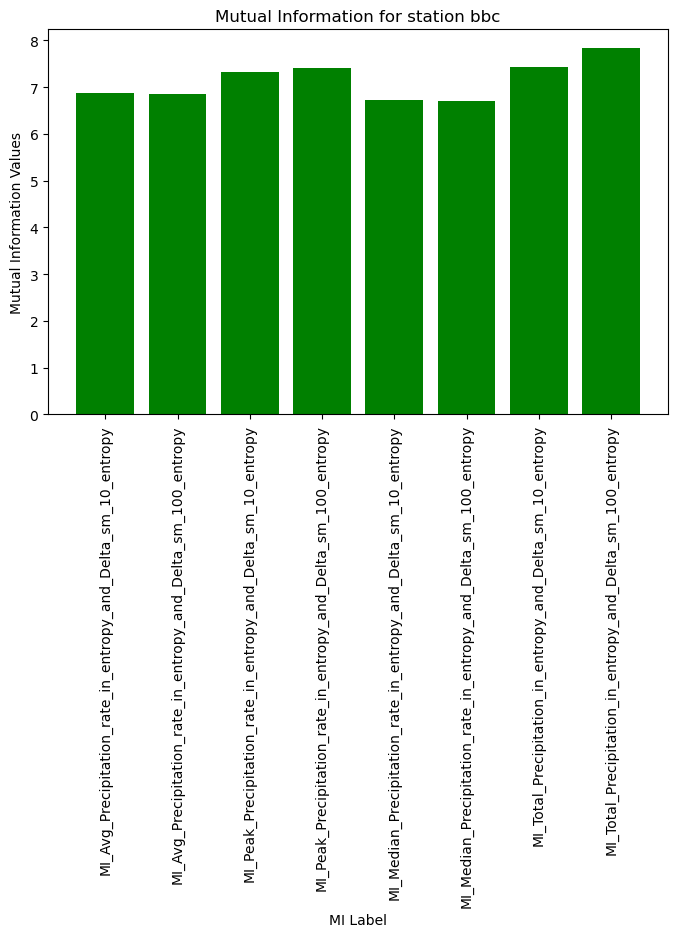

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


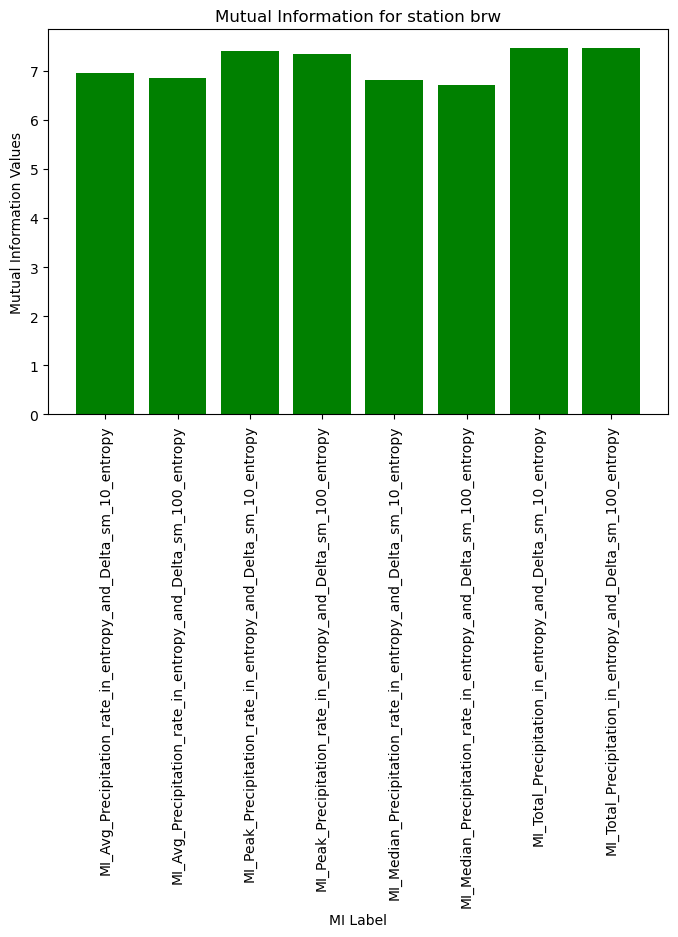

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


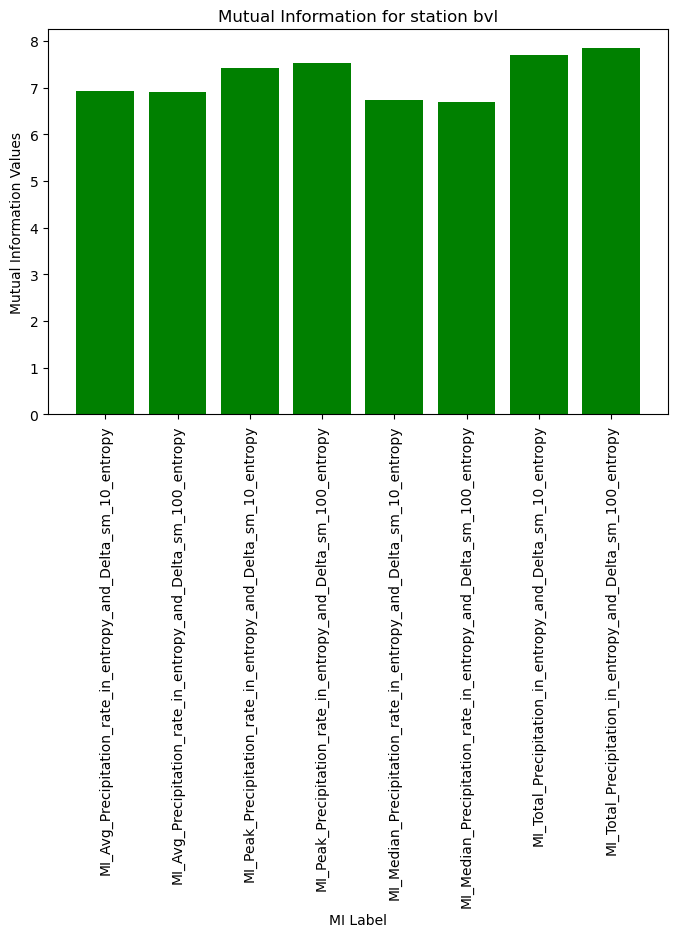

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


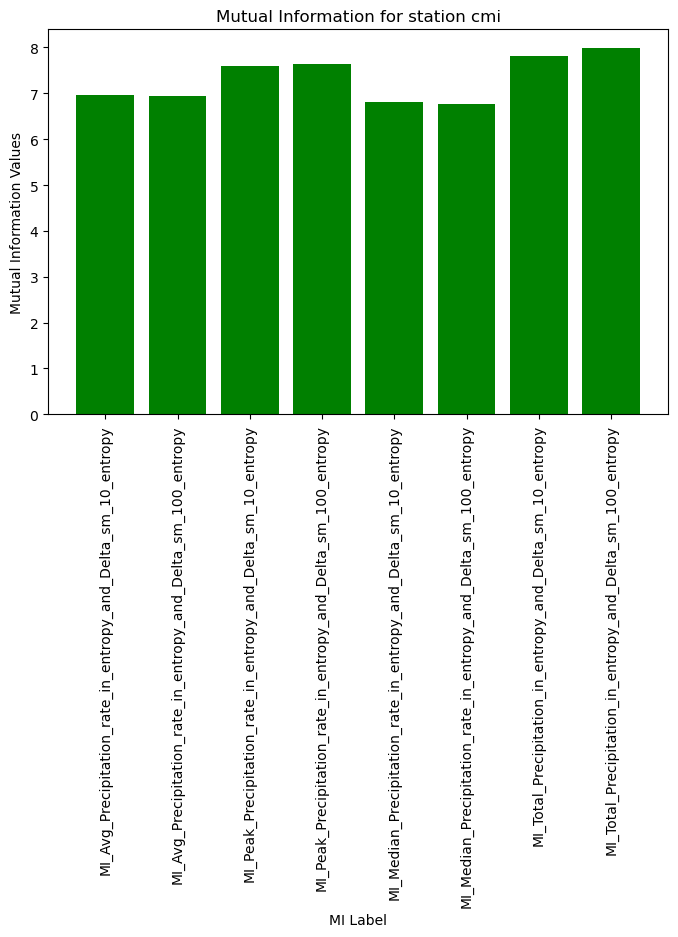

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


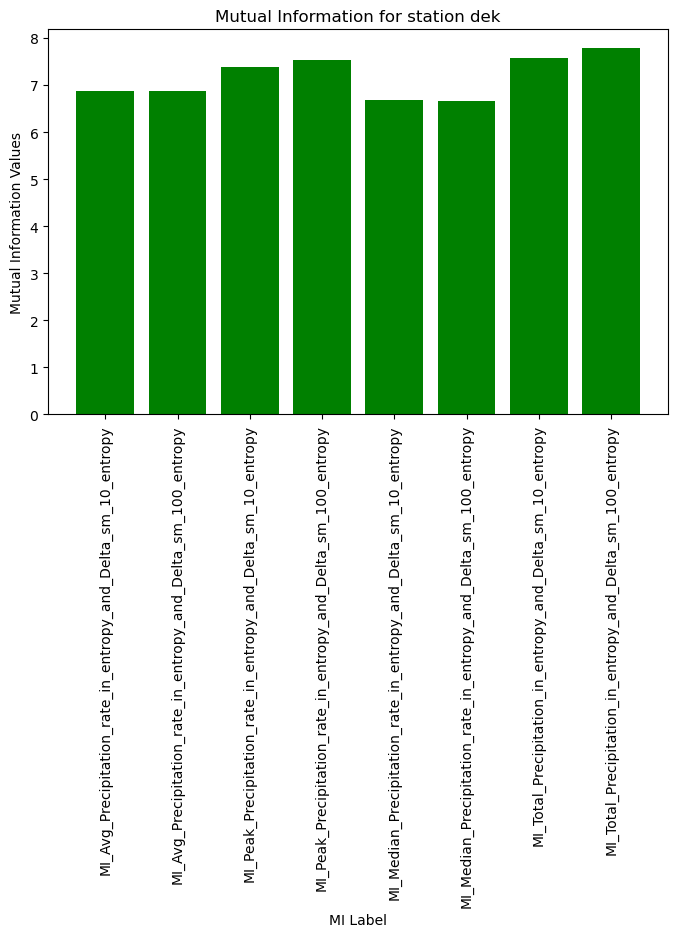

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


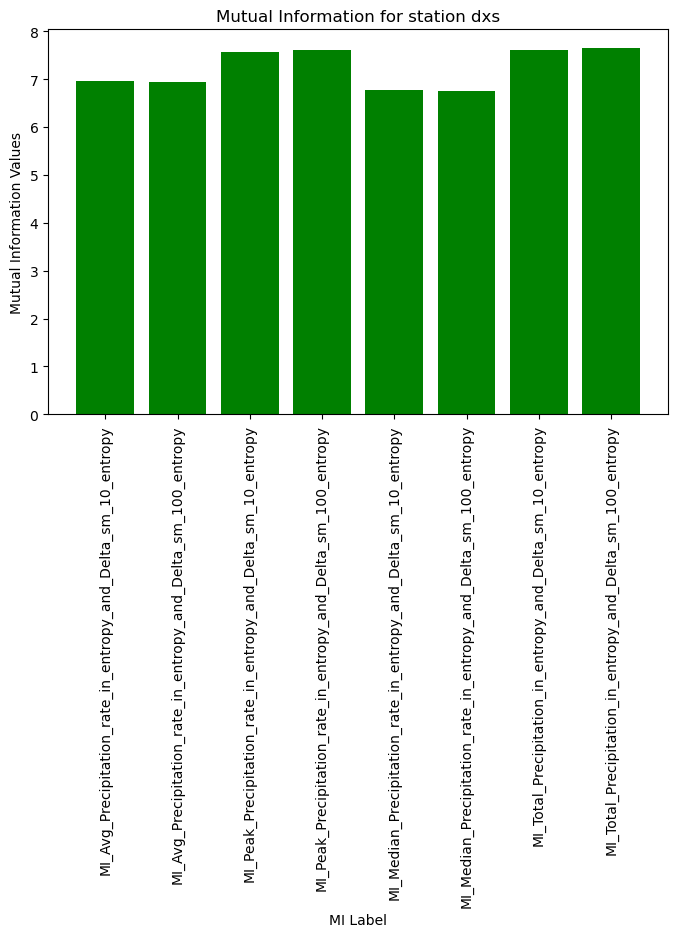

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


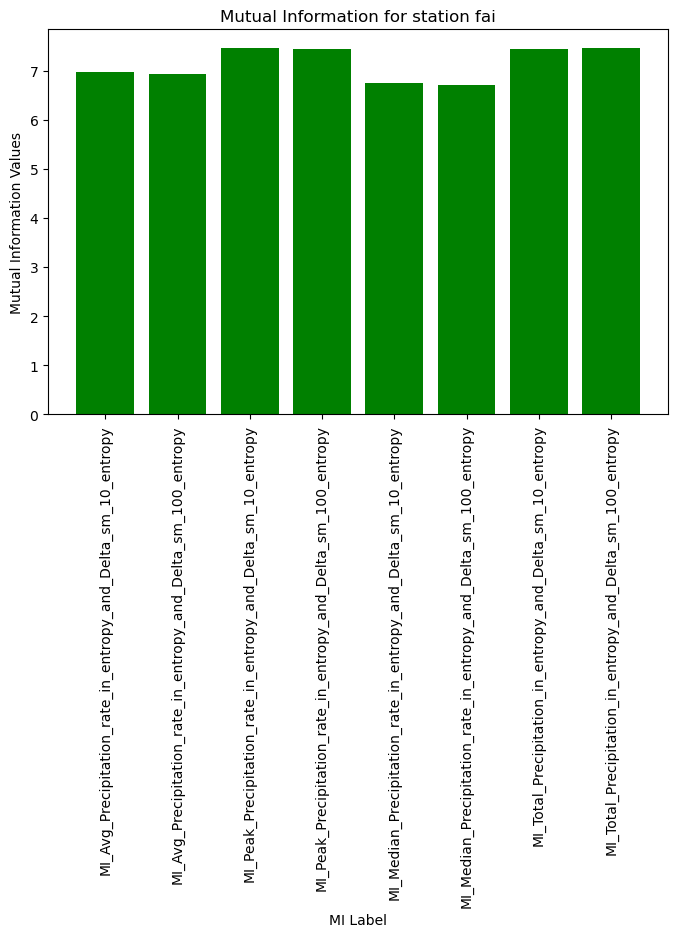

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


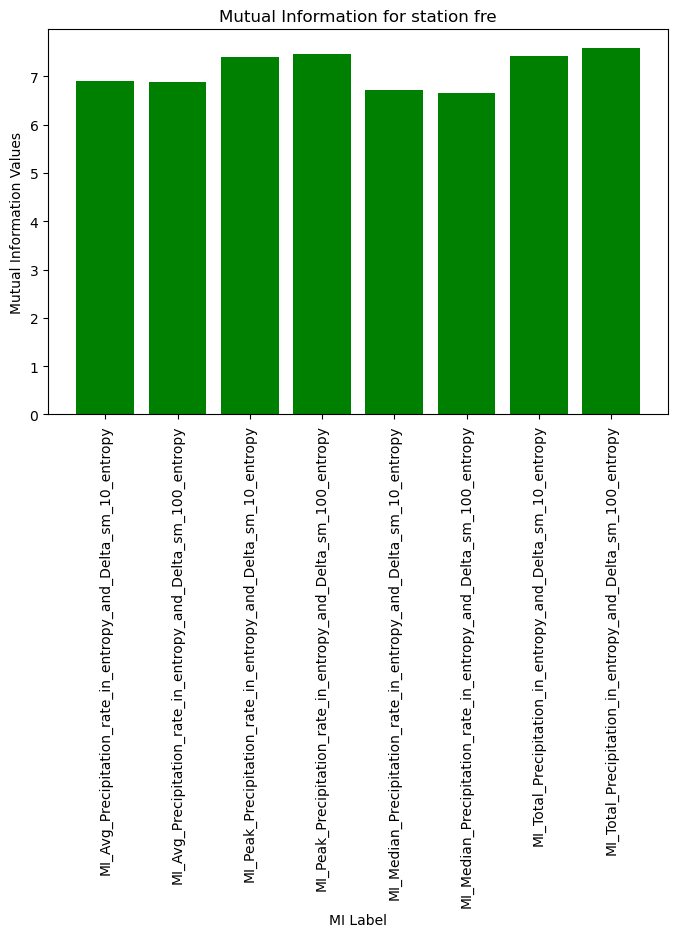

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


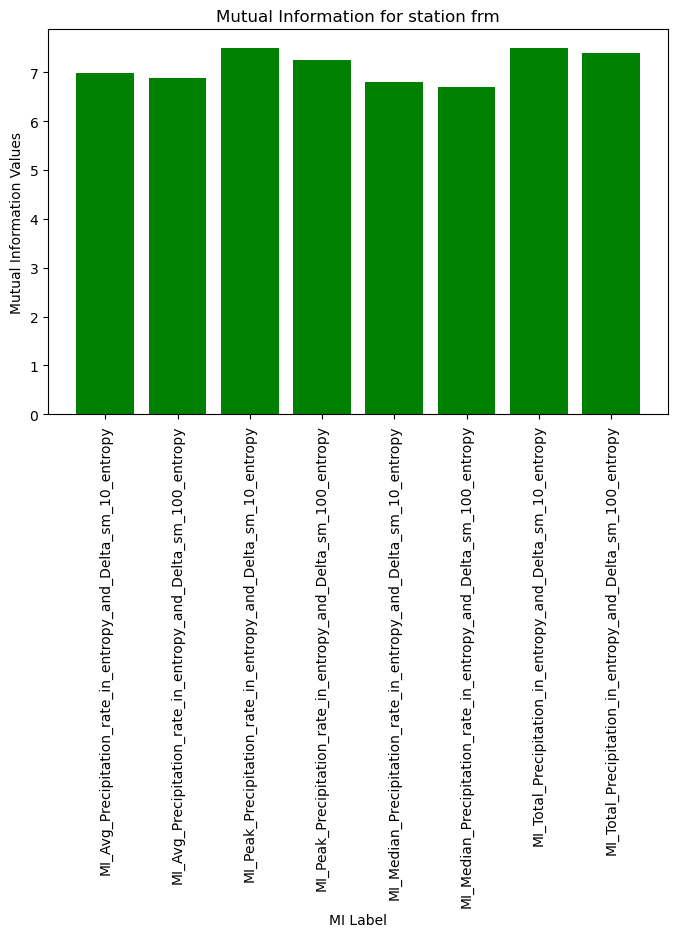

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


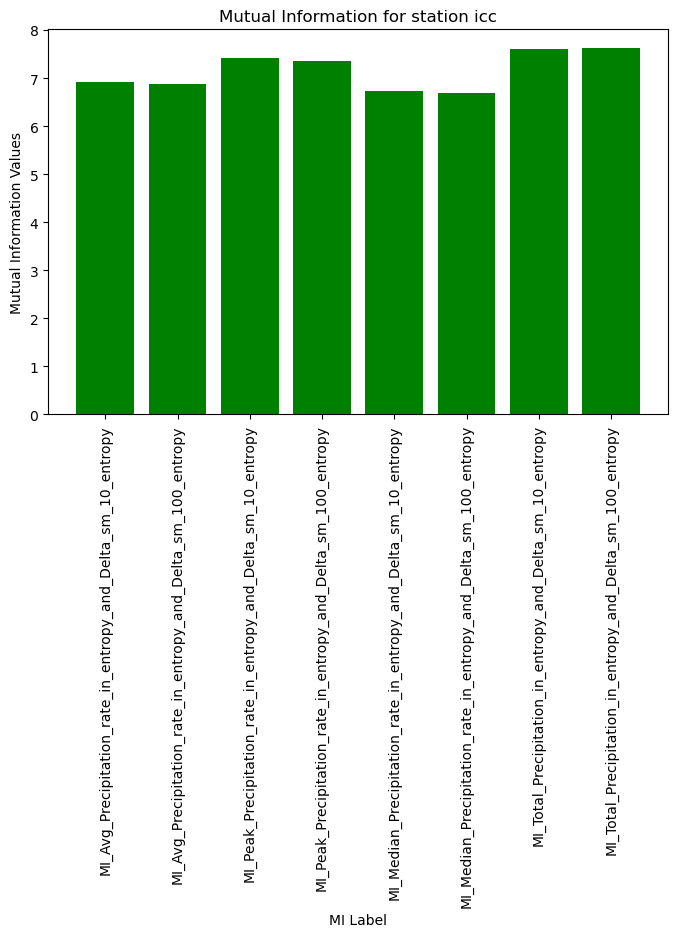

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


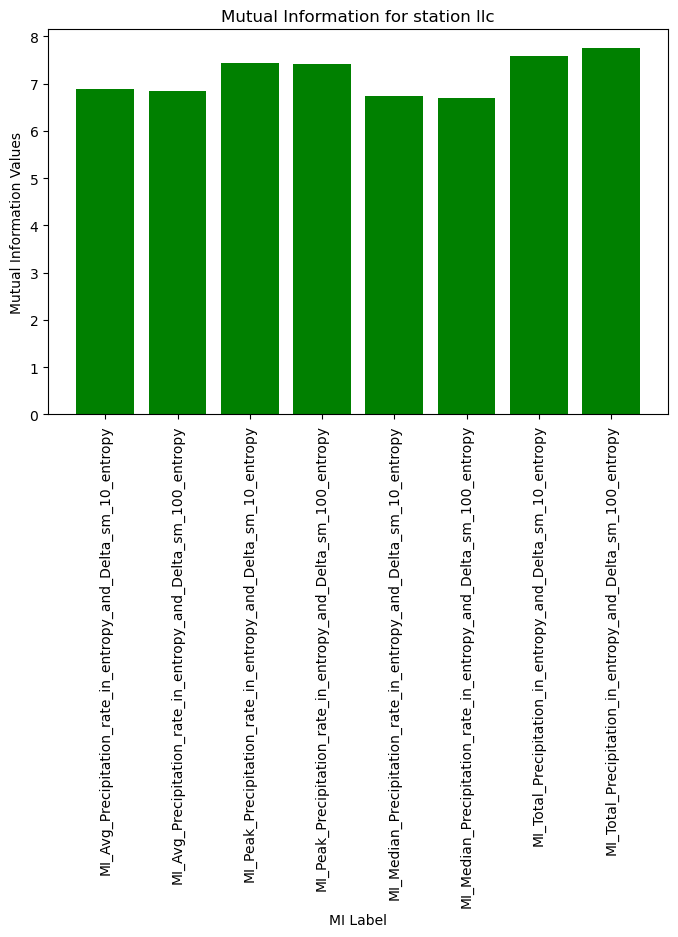

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


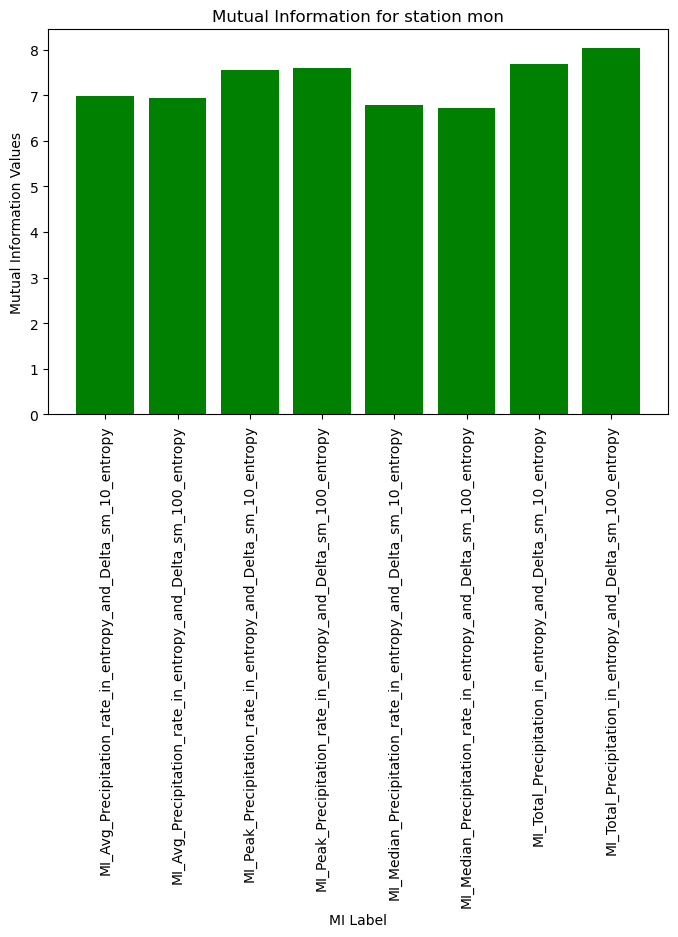

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


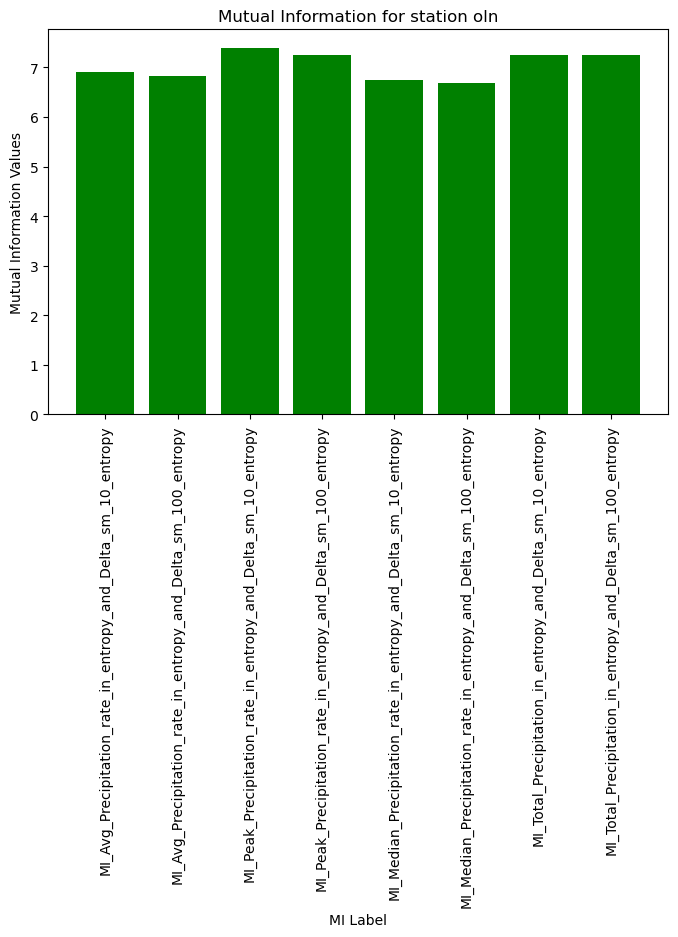

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


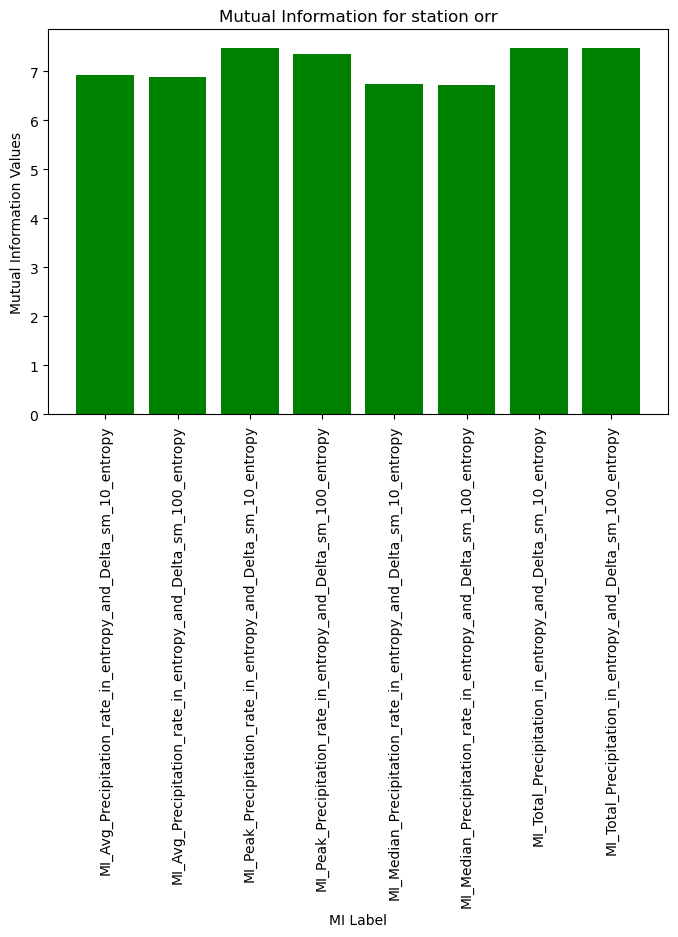

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


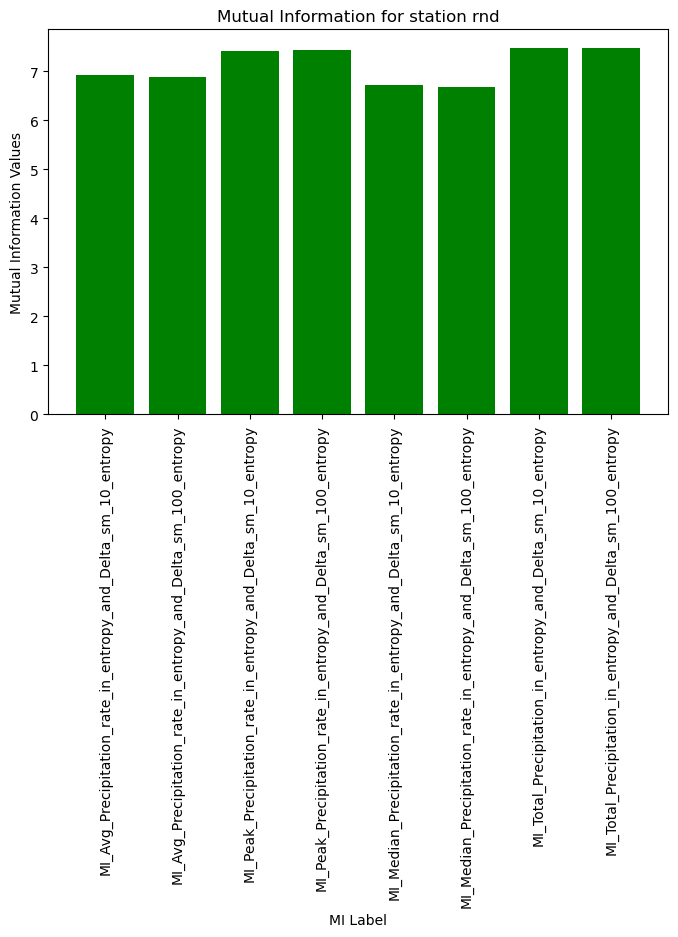

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


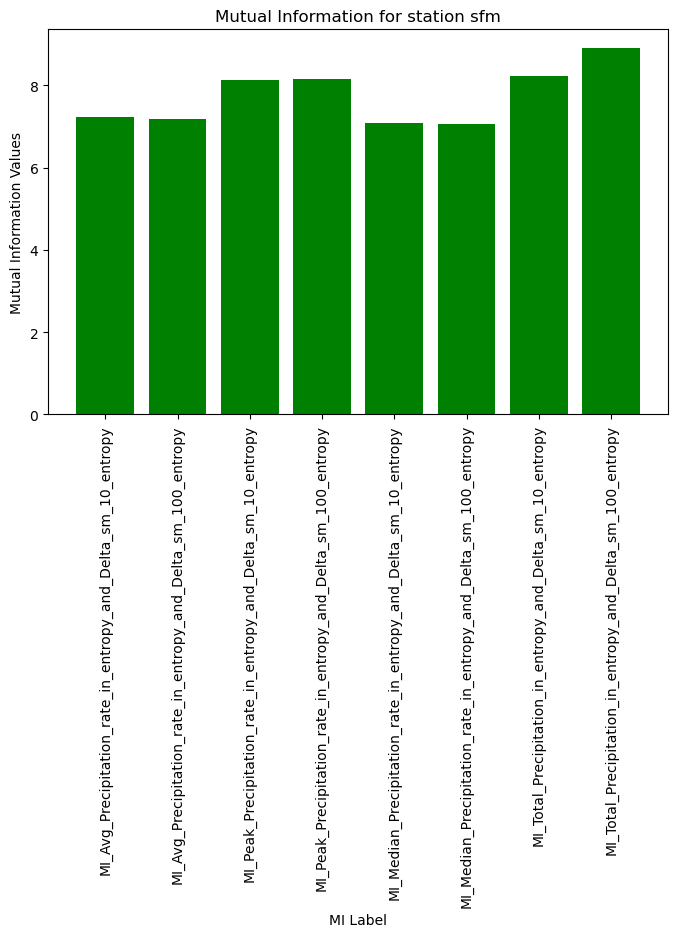

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


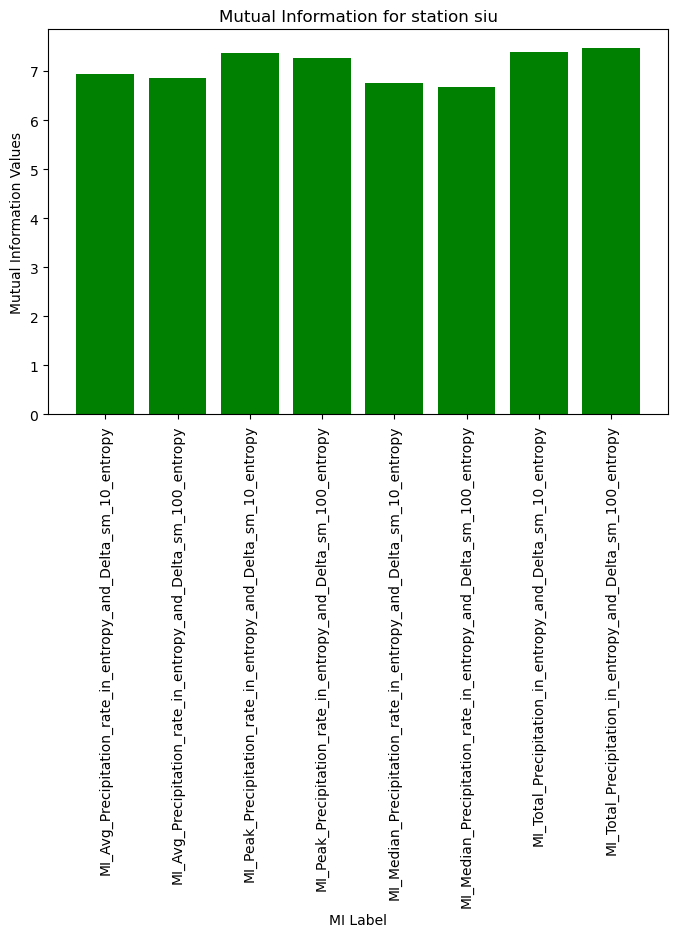

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


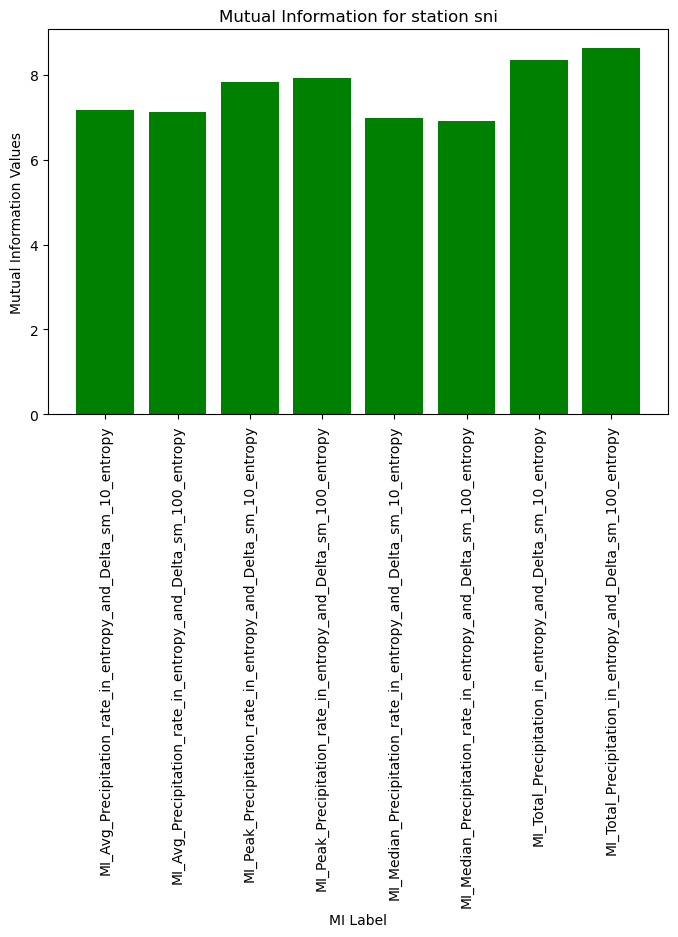

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


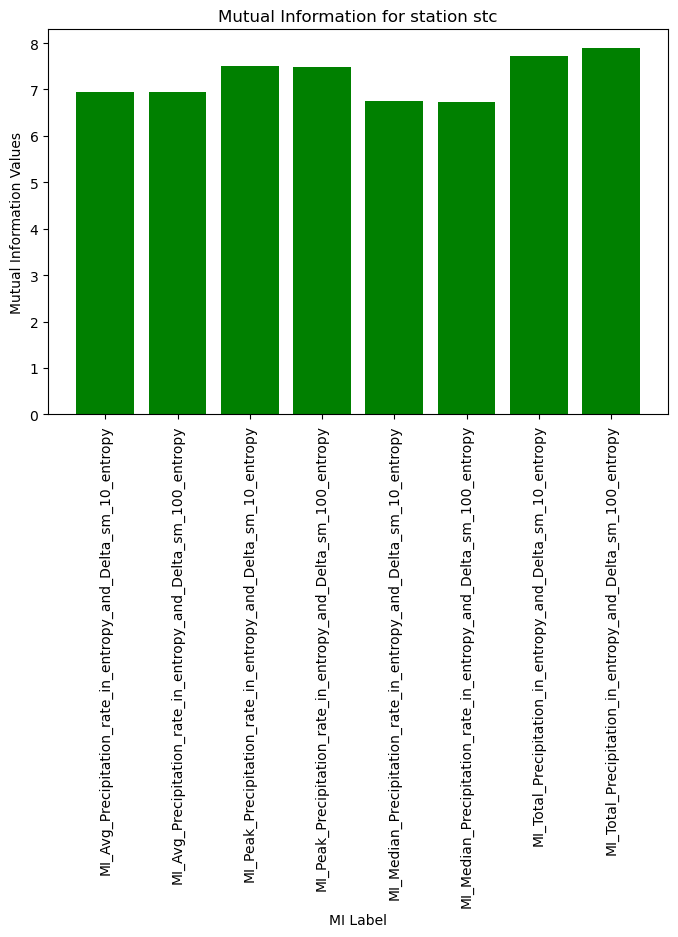

/tmp/ipykernel_2926777/1204212436.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability


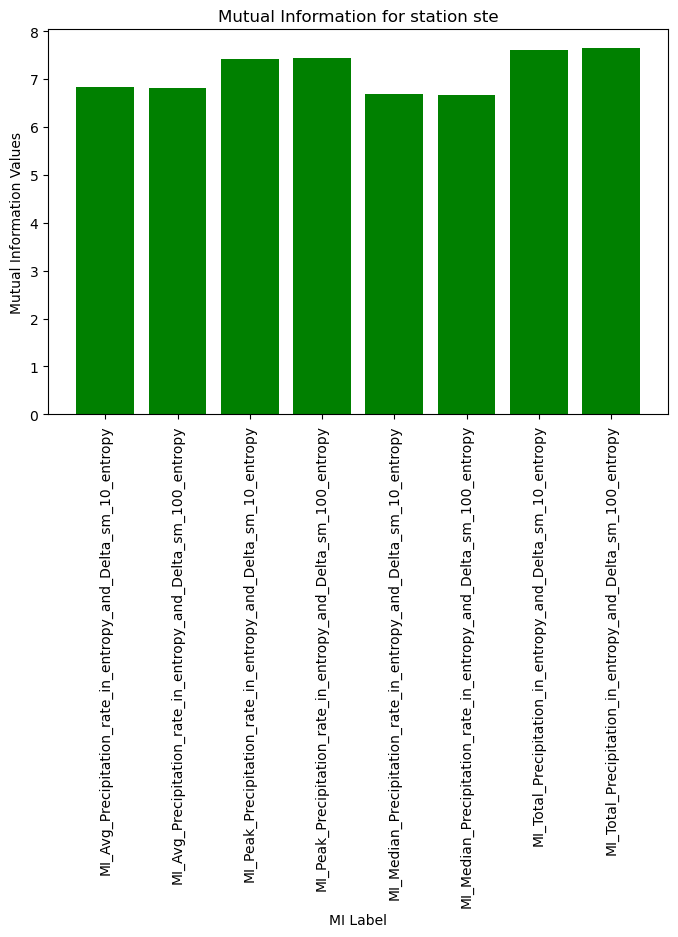

In [21]:
stations = MIs.station.unique()

for s in stations:
    station_MI = MIs.loc[MIs['station'] == s]
    fig, ax = plt.subplots(figsize = (8,5))
    ax.bar(station_MI.MI_label, station_MI.mutual_information, color = 'green')
    ax.set_title(f"Mutual Information for station {s}")
    ax.set_xlabel("MI Label")
    ax.set_ylabel("Mutual Information Values")
    ax.set_xticklabels(station_MI['MI_label'], rotation=90)  # rotate for readability
    plt.show()
    